# Deep Hedging in Black-Scholes World: 5 Variants (JAX Backend)
This notebook trains neural network deep hedging agents across 5 canonical Black-Scholes configurations:
1. `bs_base`: Base setup with positive drift (drift=0.1, CVaR, lambda=1.0, 400 epochs)
2. `bs_exp2`: Exponential utility under zero drift (exp2, lambda=10.0, 400 epochs)
3. `bs_nodrift`: CVaR under zero drift with gradient clipping (cvar, lambda=1.0, 600 epochs)
4. `bs_nodrift_exp2`: Exponential utility under zero drift with clipping (exp2, lambda=10.0, lr=0.001, 600 epochs)
5. `bs_small`: Smaller sample size with higher risk aversion (cvar, lambda=2.0, 10 epochs)

**Backend**: JAX / Flax functional engine.
**Self-contained**: Uses local `dh_jax` module.


In [1]:
import os, sys
from pathlib import Path

NB_DIR = Path.cwd()
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from dh_jax.world import WorldConfig, simulate
from dh_jax.model import AgentConfig, GymConfig
from dh_jax.train import TrainConfig, fit
from dh_jax.plotting import plot_training, plot_blackscholes
from configs.catalog import get_config

MODE = os.environ.get("DH_MODE", "original")
def get_epochs(default_ep):
    if os.environ.get("DH_EPOCHS"):
        return int(os.environ.get("DH_EPOCHS"))
    return 2 if MODE == "smoke" else default_ep

def get_samples(default_samples):
    return min(default_samples, 500) if MODE == "smoke" else default_samples

CHECKPOINTS = os.environ.get("DH_CHECKPOINTS", "checkpoints") or None
print(f"blackscholes.ipynb initialized | Mode: {MODE} | Checkpoints: {CHECKPOINTS}")


blackscholes.ipynb initialized | Mode: smoke | Checkpoints: D:\deephedging-rewritten\results\windows_smoke_20261106_163915\isolated_checkpoints


## 1. `bs_base`: Base Black-Scholes Hedging (CVaR, Drift=0.1)


  epoch 1/2: loss 0.28423 val 0.26471 best@0 (1.57s)


  epoch 2/2: loss 0.43047 val 0.39440 best@0 (0.04s)


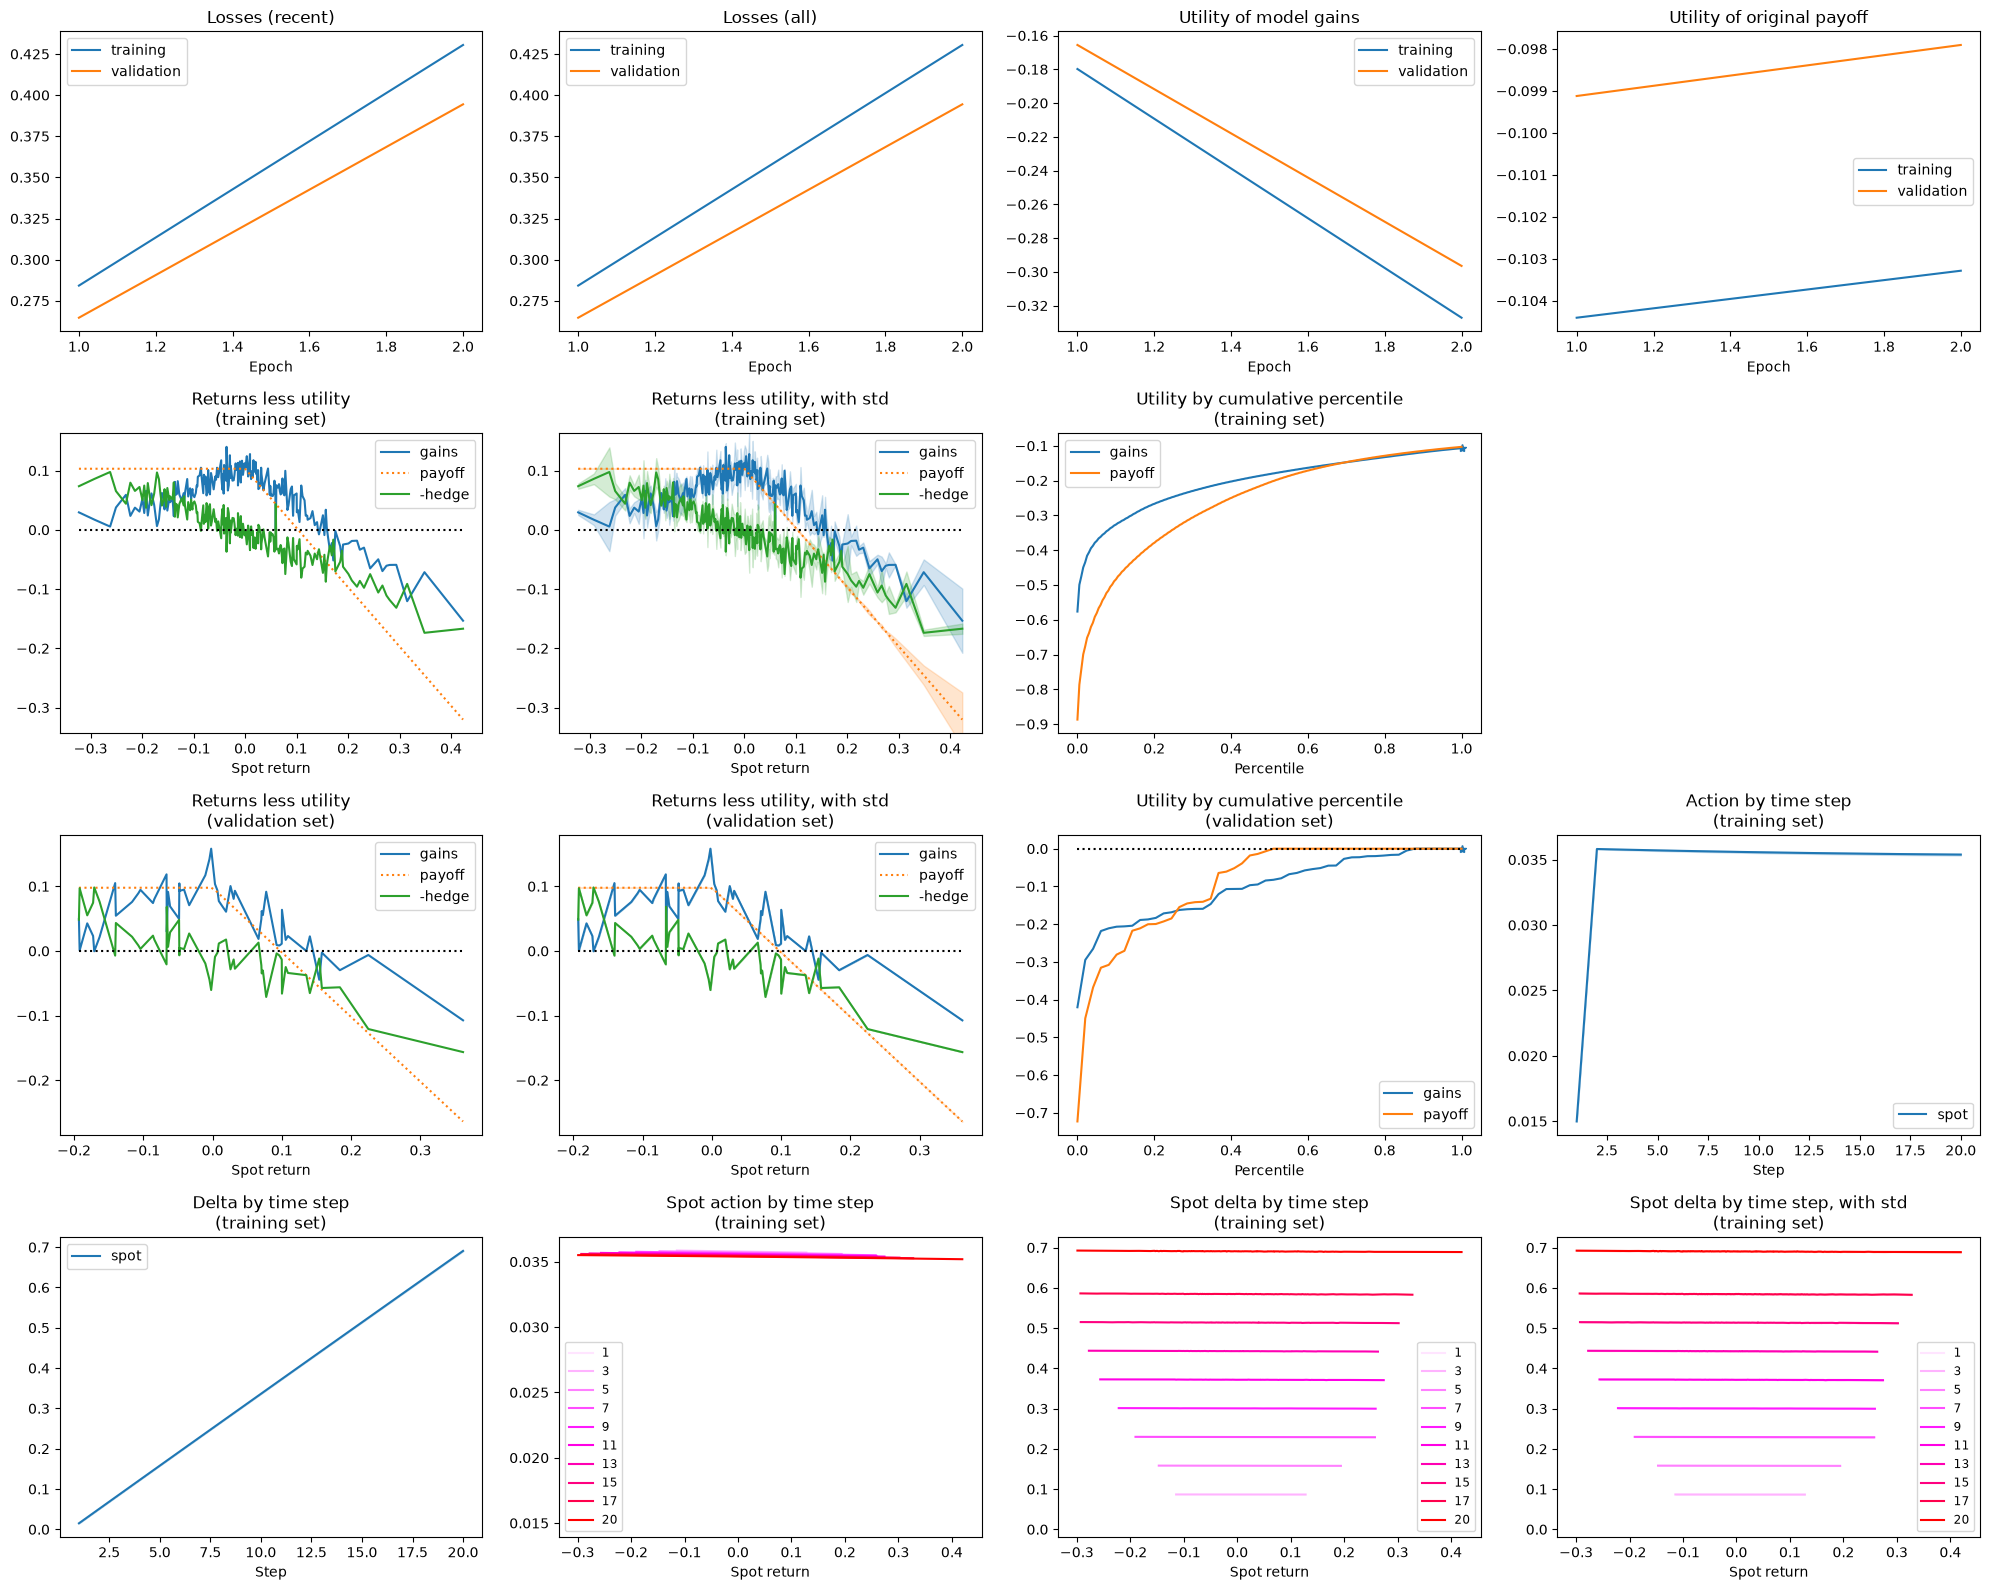

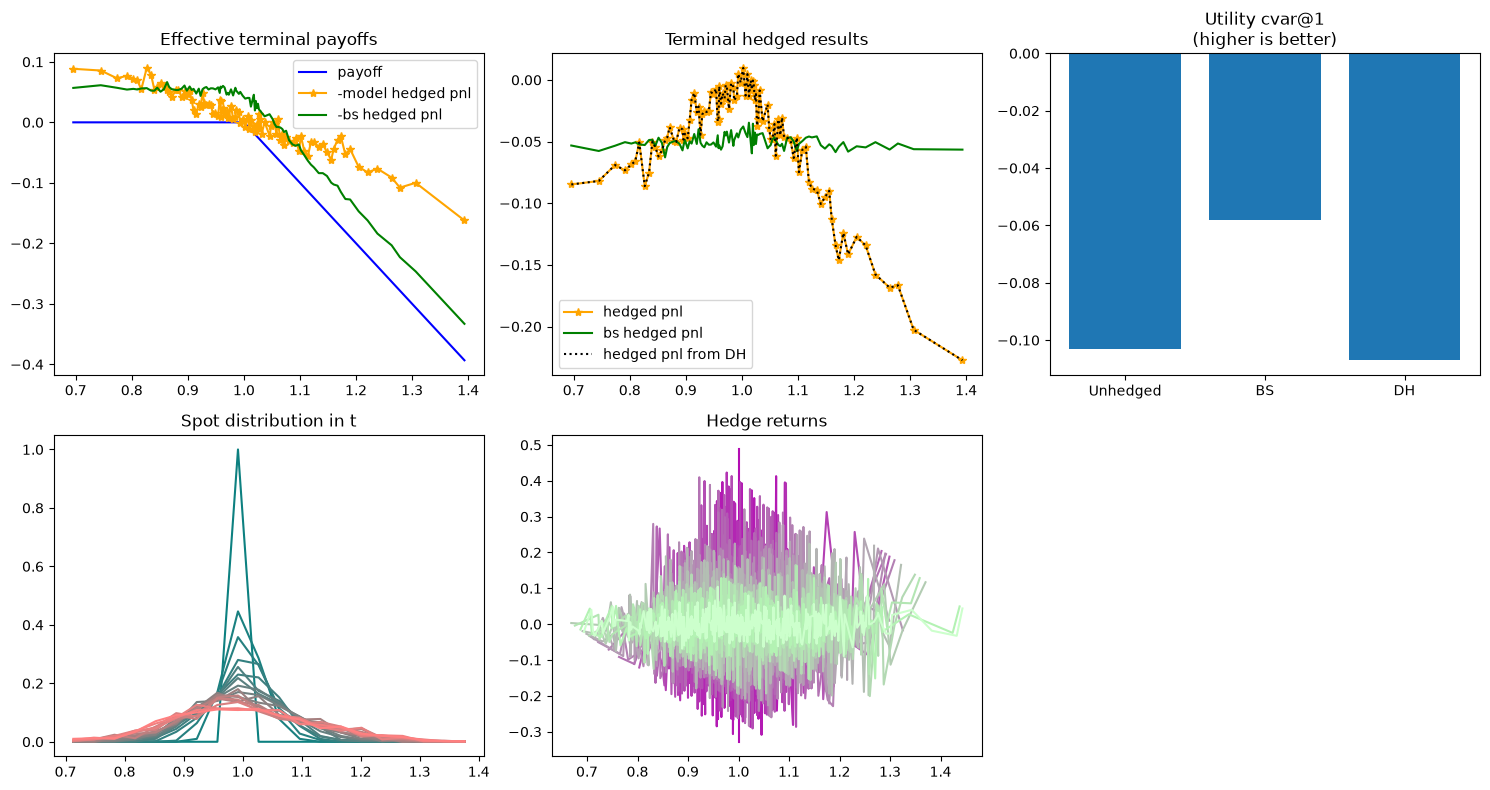

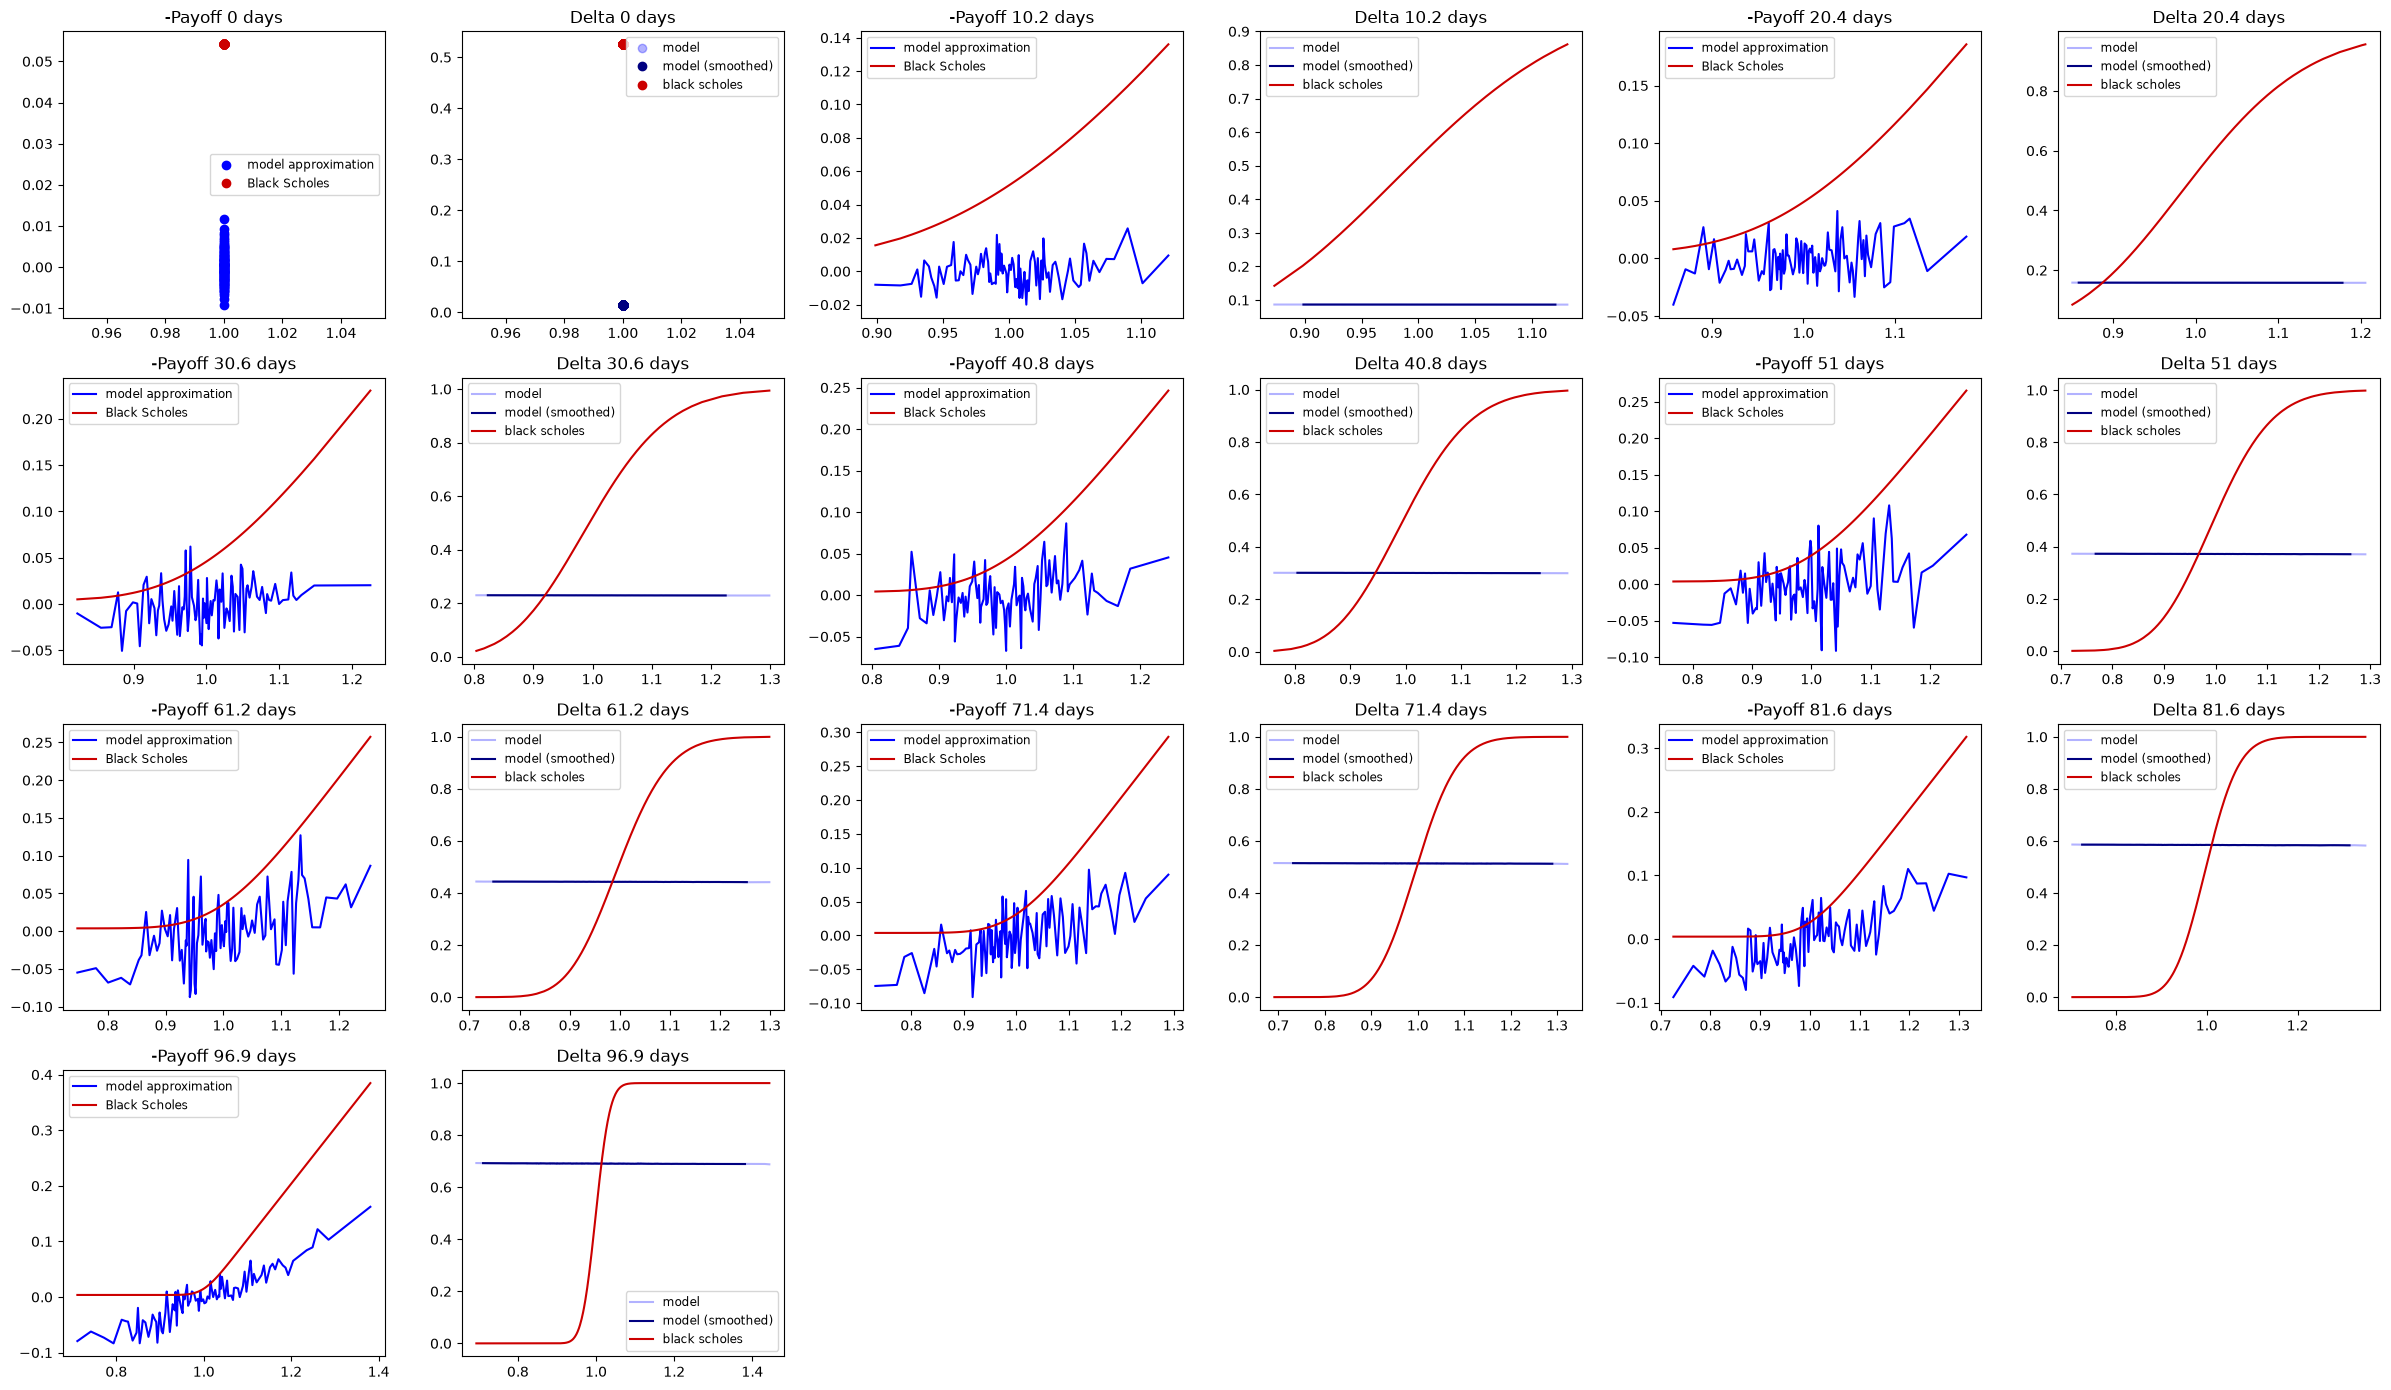

In [2]:
cfg = get_config("bs_base", mode=MODE)
n_samples = get_samples(cfg["samples"])
n_epochs = get_epochs(cfg["epochs"])

world_cfg = WorldConfig(samples=n_samples, steps=cfg["steps"], black_scholes=True, rvol=cfg["rvol"], drift=cfg["drift"], cost_s=cfg["cost_s"])
gym = GymConfig(agent=AgentConfig(depth=cfg["depth"], width=cfg["width"], activation=cfg["activation"]), utility=cfg["utility"], lmbda=cfg["lmbda"])
train_cfg = TrainConfig(epochs=n_epochs, batch_size=min(cfg["batch_size"], n_samples), learning_rate=cfg["lr"])

world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 10, 50), seed=1)
base_fit = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 4), checkpoint_dir=CHECKPOINTS)

try:
    plot_training(base_fit.result, base_fit.train, base_fit.val, world, val_world)
    plt.show()
    plot_blackscholes(world, base_fit.train, gym, vol=world_cfg.rvol)
    plt.show()
except Exception as e:
    print(f"Plot note: {e}")


## 2. `bs_exp2`: Exponential Utility (Exp2, Lambda=10.0, Drift=0.0)


  epoch 1/2: loss 0.25323 val 0.23418 best@0 (1.55s)


  epoch 2/2: loss 0.62657 val 0.53788 best@0 (0.05s)


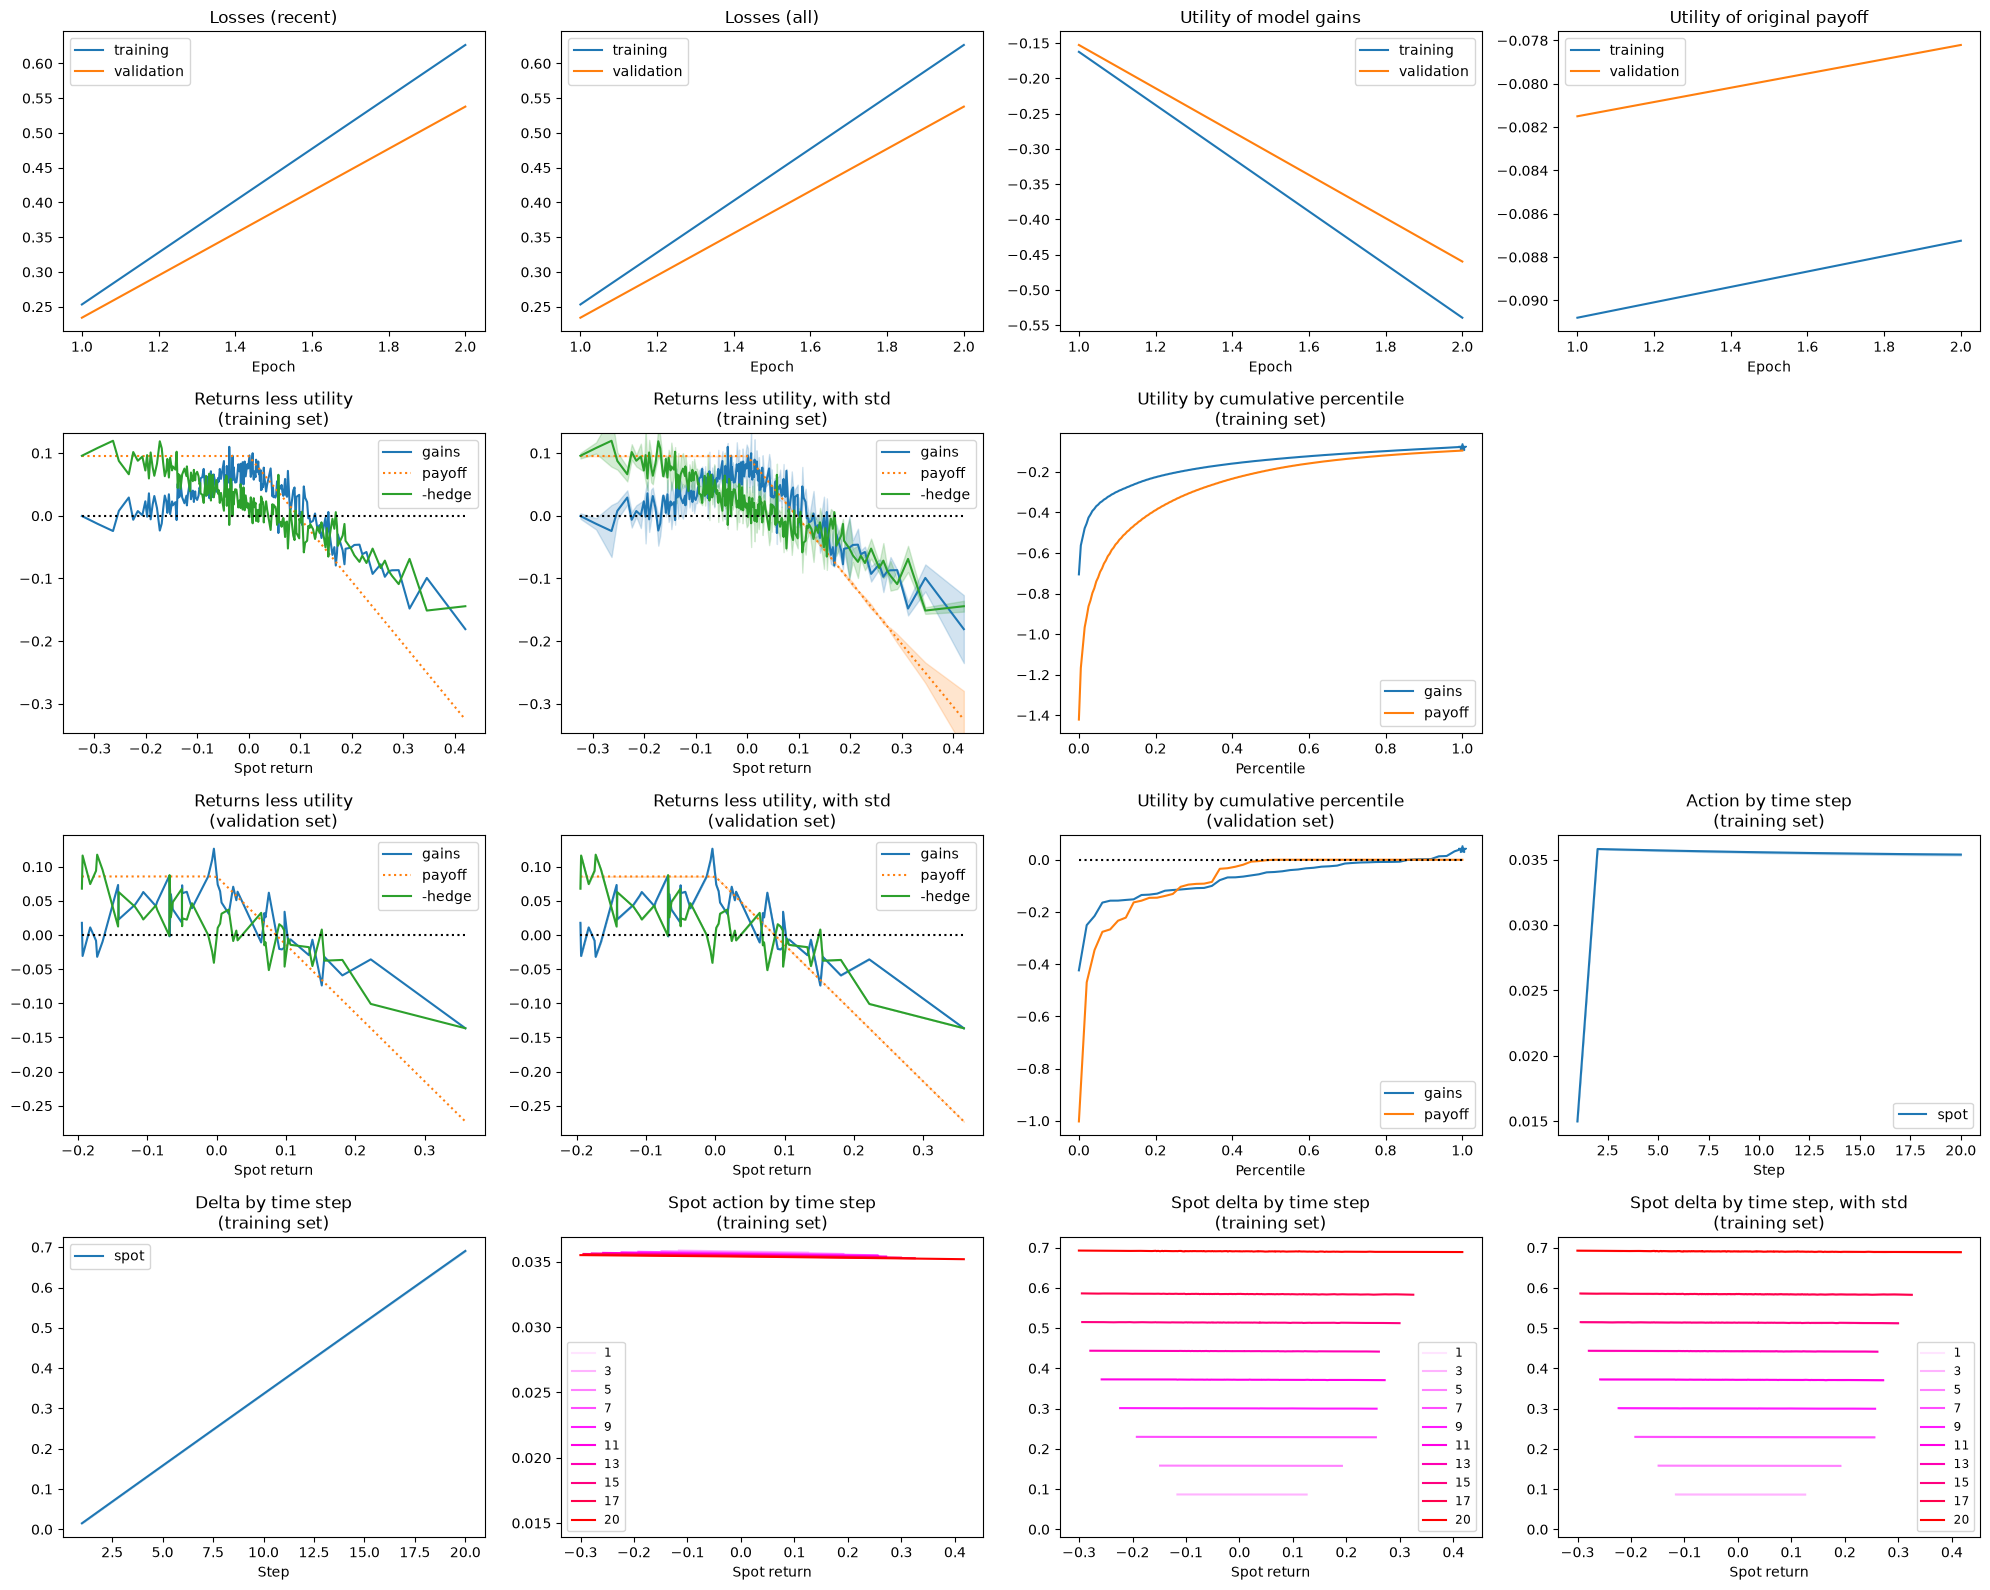

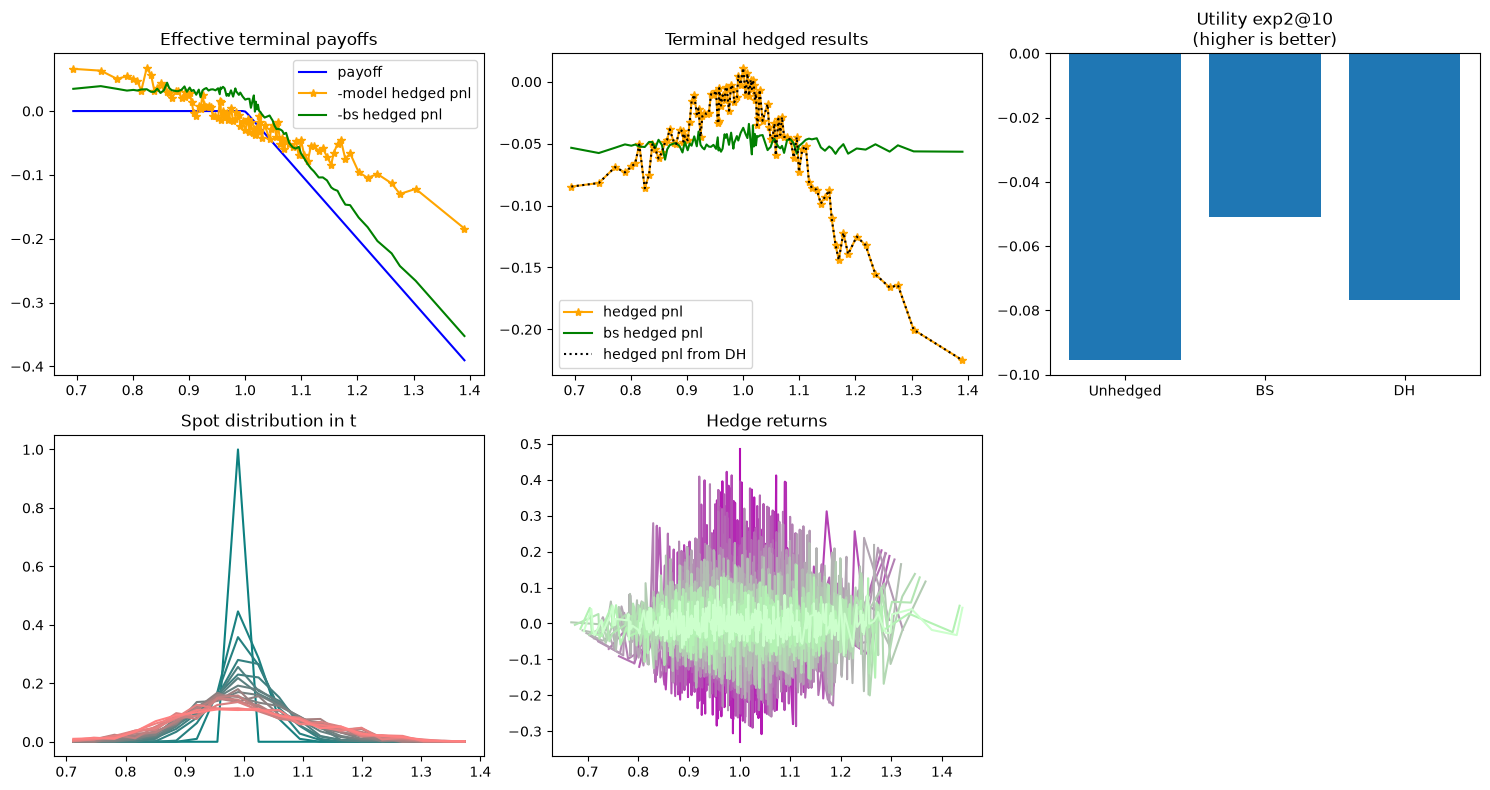

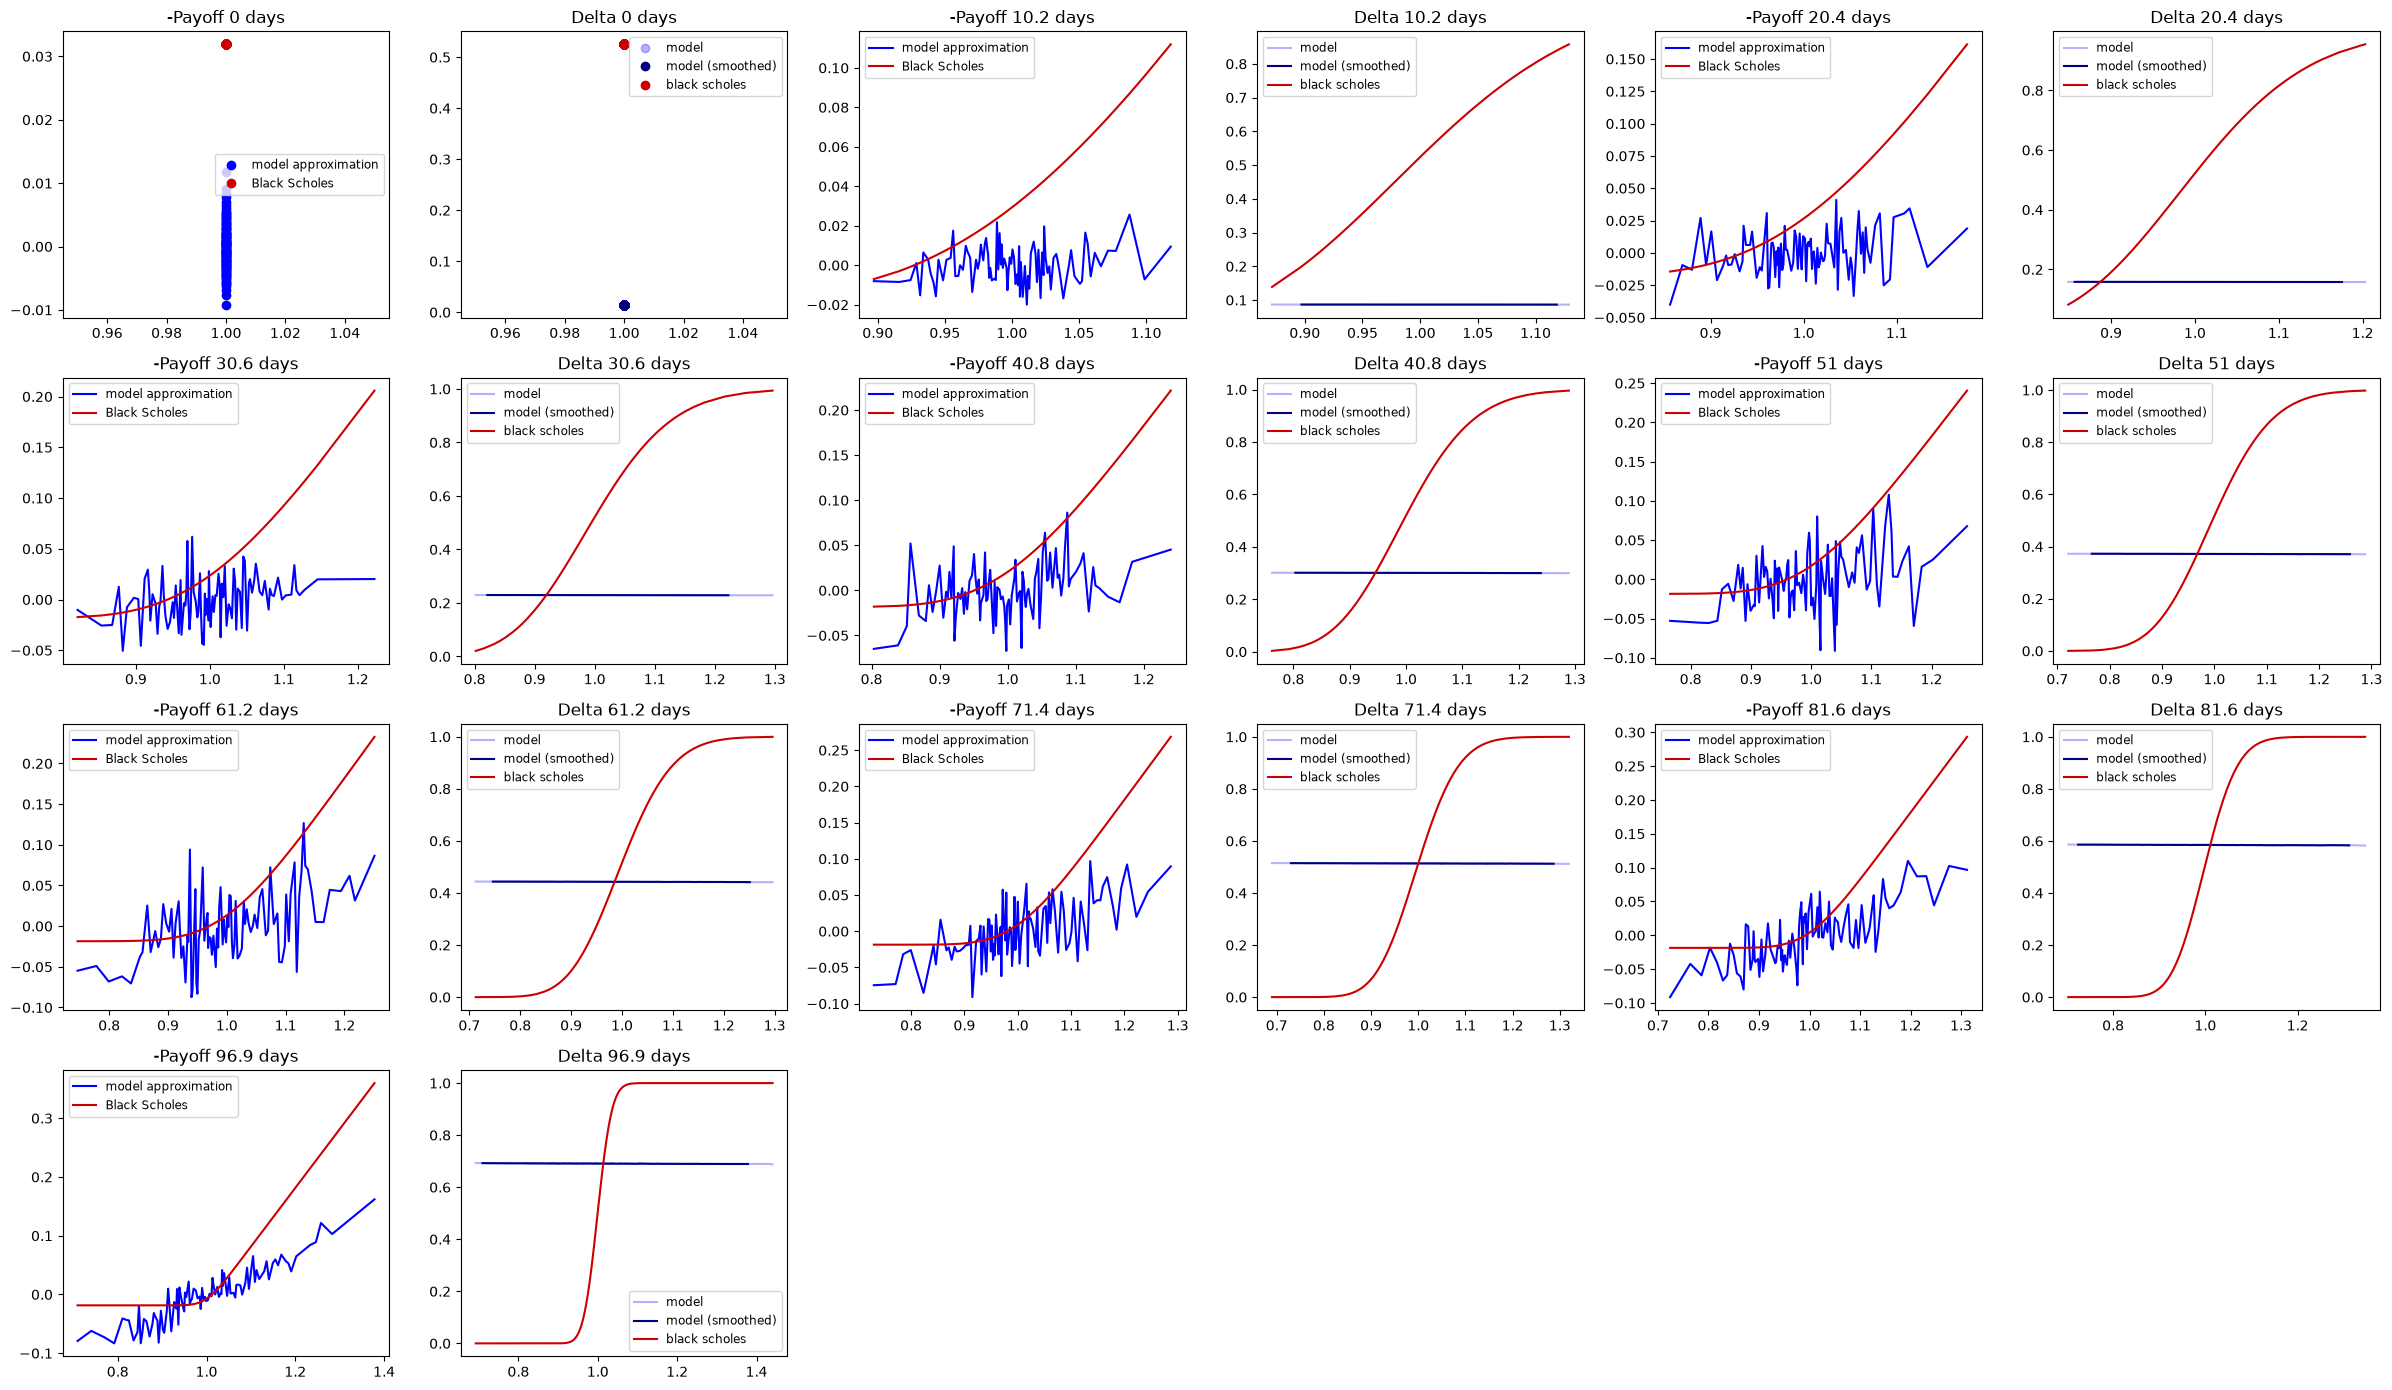

In [4]:
cfg = get_config("bs_exp2", mode=MODE)
n_samples = get_samples(cfg["samples"])
n_epochs = get_epochs(cfg["epochs"])

world_cfg = WorldConfig(samples=n_samples, steps=cfg["steps"], black_scholes=True, rvol=cfg["rvol"], drift=cfg["drift"], cost_s=cfg["cost_s"])
gym = GymConfig(agent=AgentConfig(depth=cfg["depth"], width=cfg["width"], activation=cfg["activation"]), utility=cfg["utility"], lmbda=cfg["lmbda"])
train_cfg = TrainConfig(epochs=n_epochs, batch_size=min(cfg["batch_size"], n_samples), learning_rate=cfg["lr"])

world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 10, 50), seed=1)
exp2_fit = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 4), checkpoint_dir=CHECKPOINTS)

try:
    plot_training(exp2_fit.result, exp2_fit.train, exp2_fit.val, world, val_world)
    plt.show()
    plot_blackscholes(world, exp2_fit.train, gym, vol=world_cfg.rvol)
    plt.show()
except Exception as e:
    print(f"Plot note: {e}")


## 3. `bs_nodrift`: Zero Drift with Gradient Clipping (CVaR, Lambda=1.0)


  epoch 1/2: loss 0.30547 val 0.28277 best@0 (1.32s)


  epoch 2/2: loss 0.36723 val 0.33875 best@0 (0.03s)


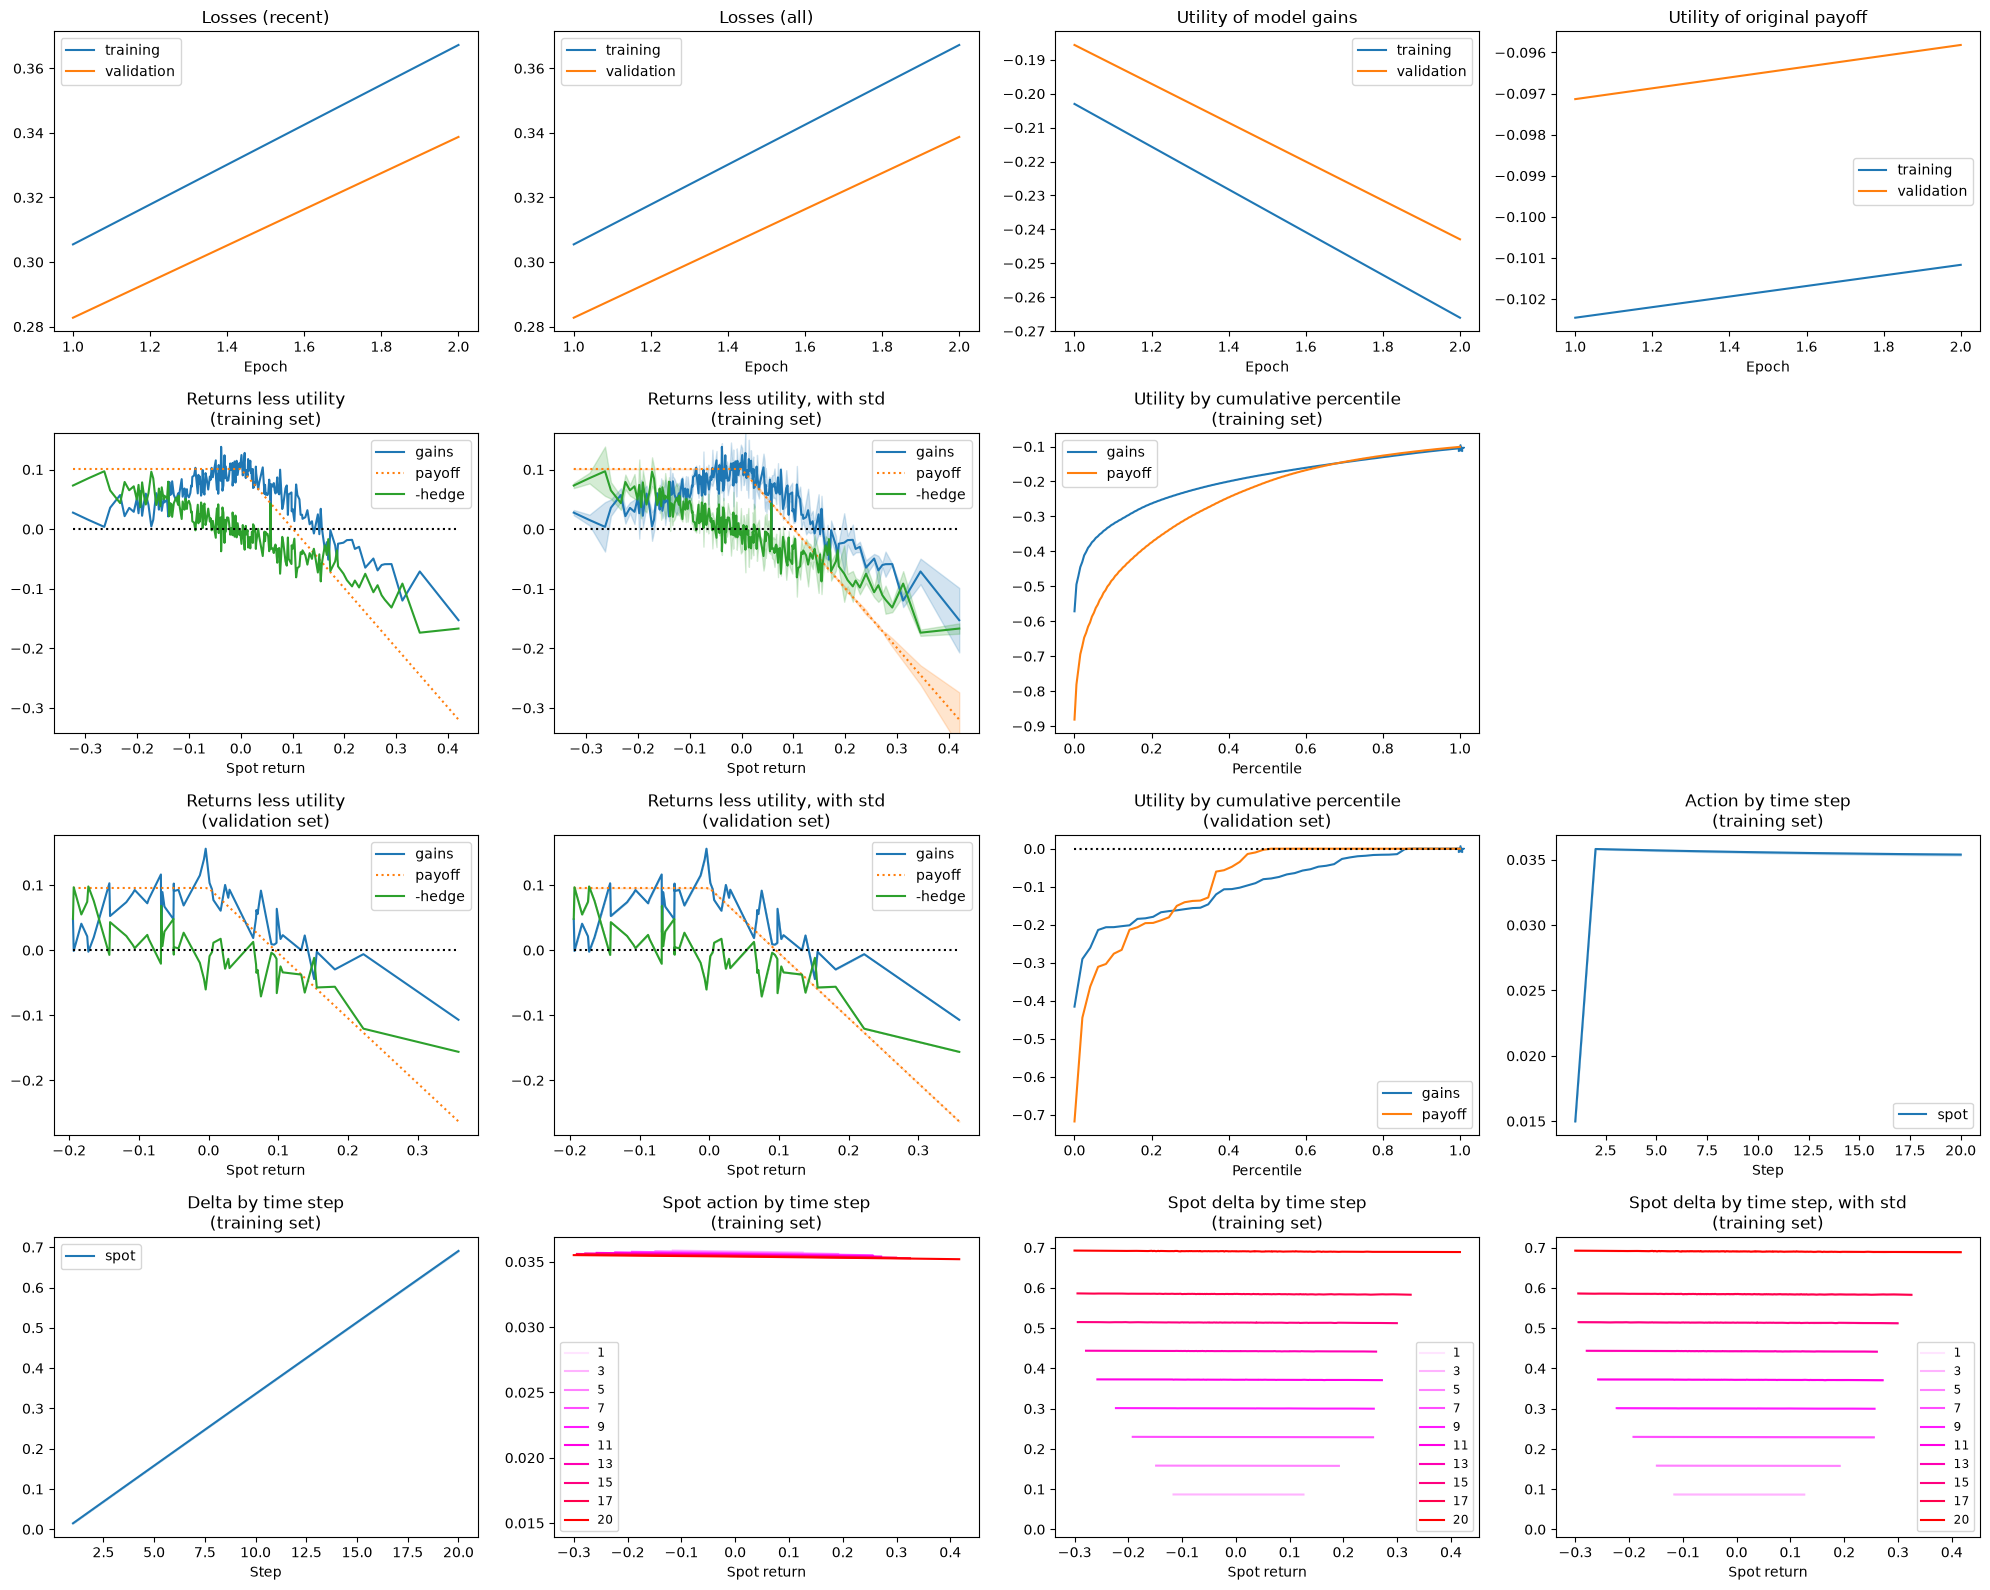

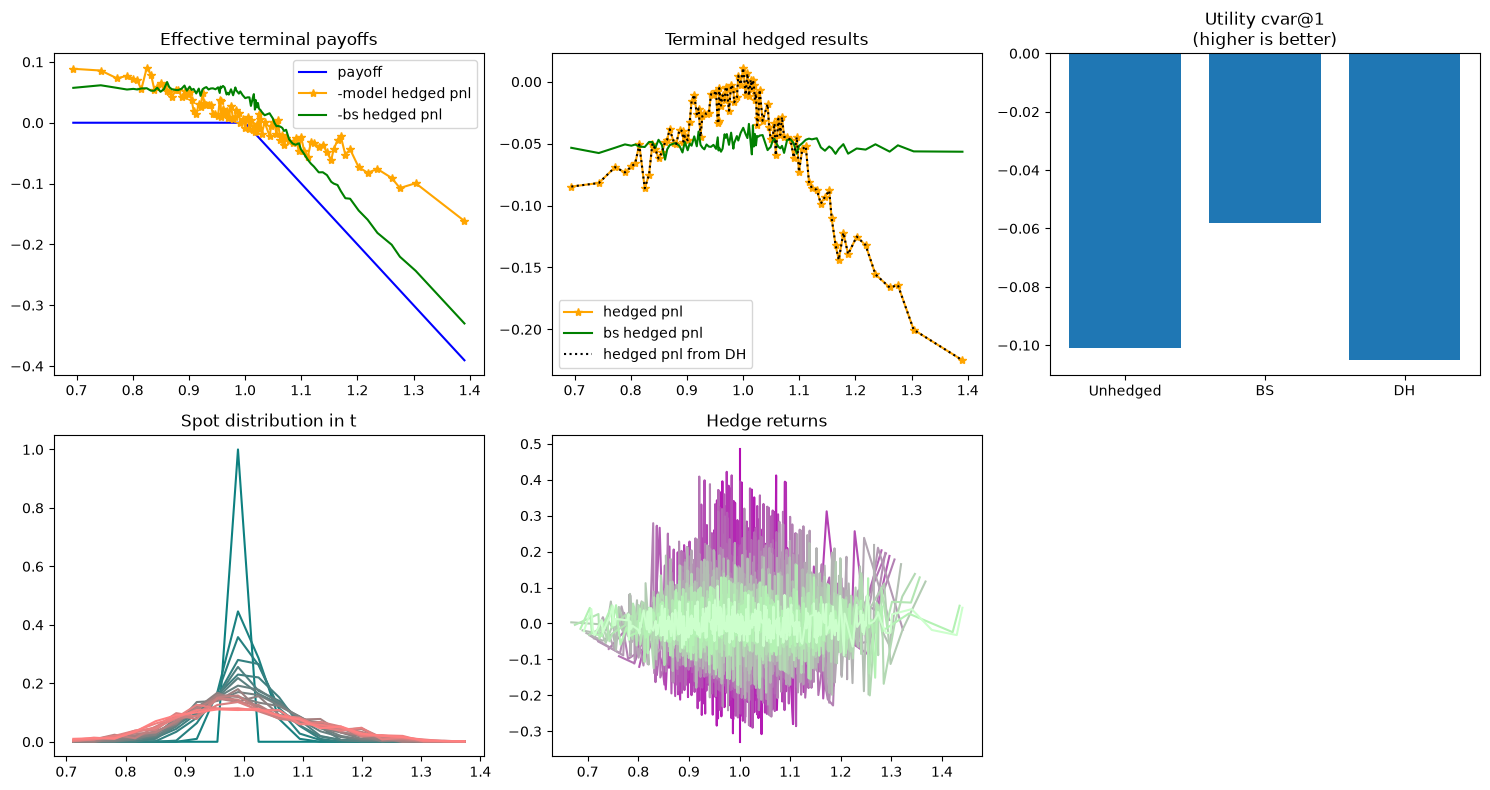

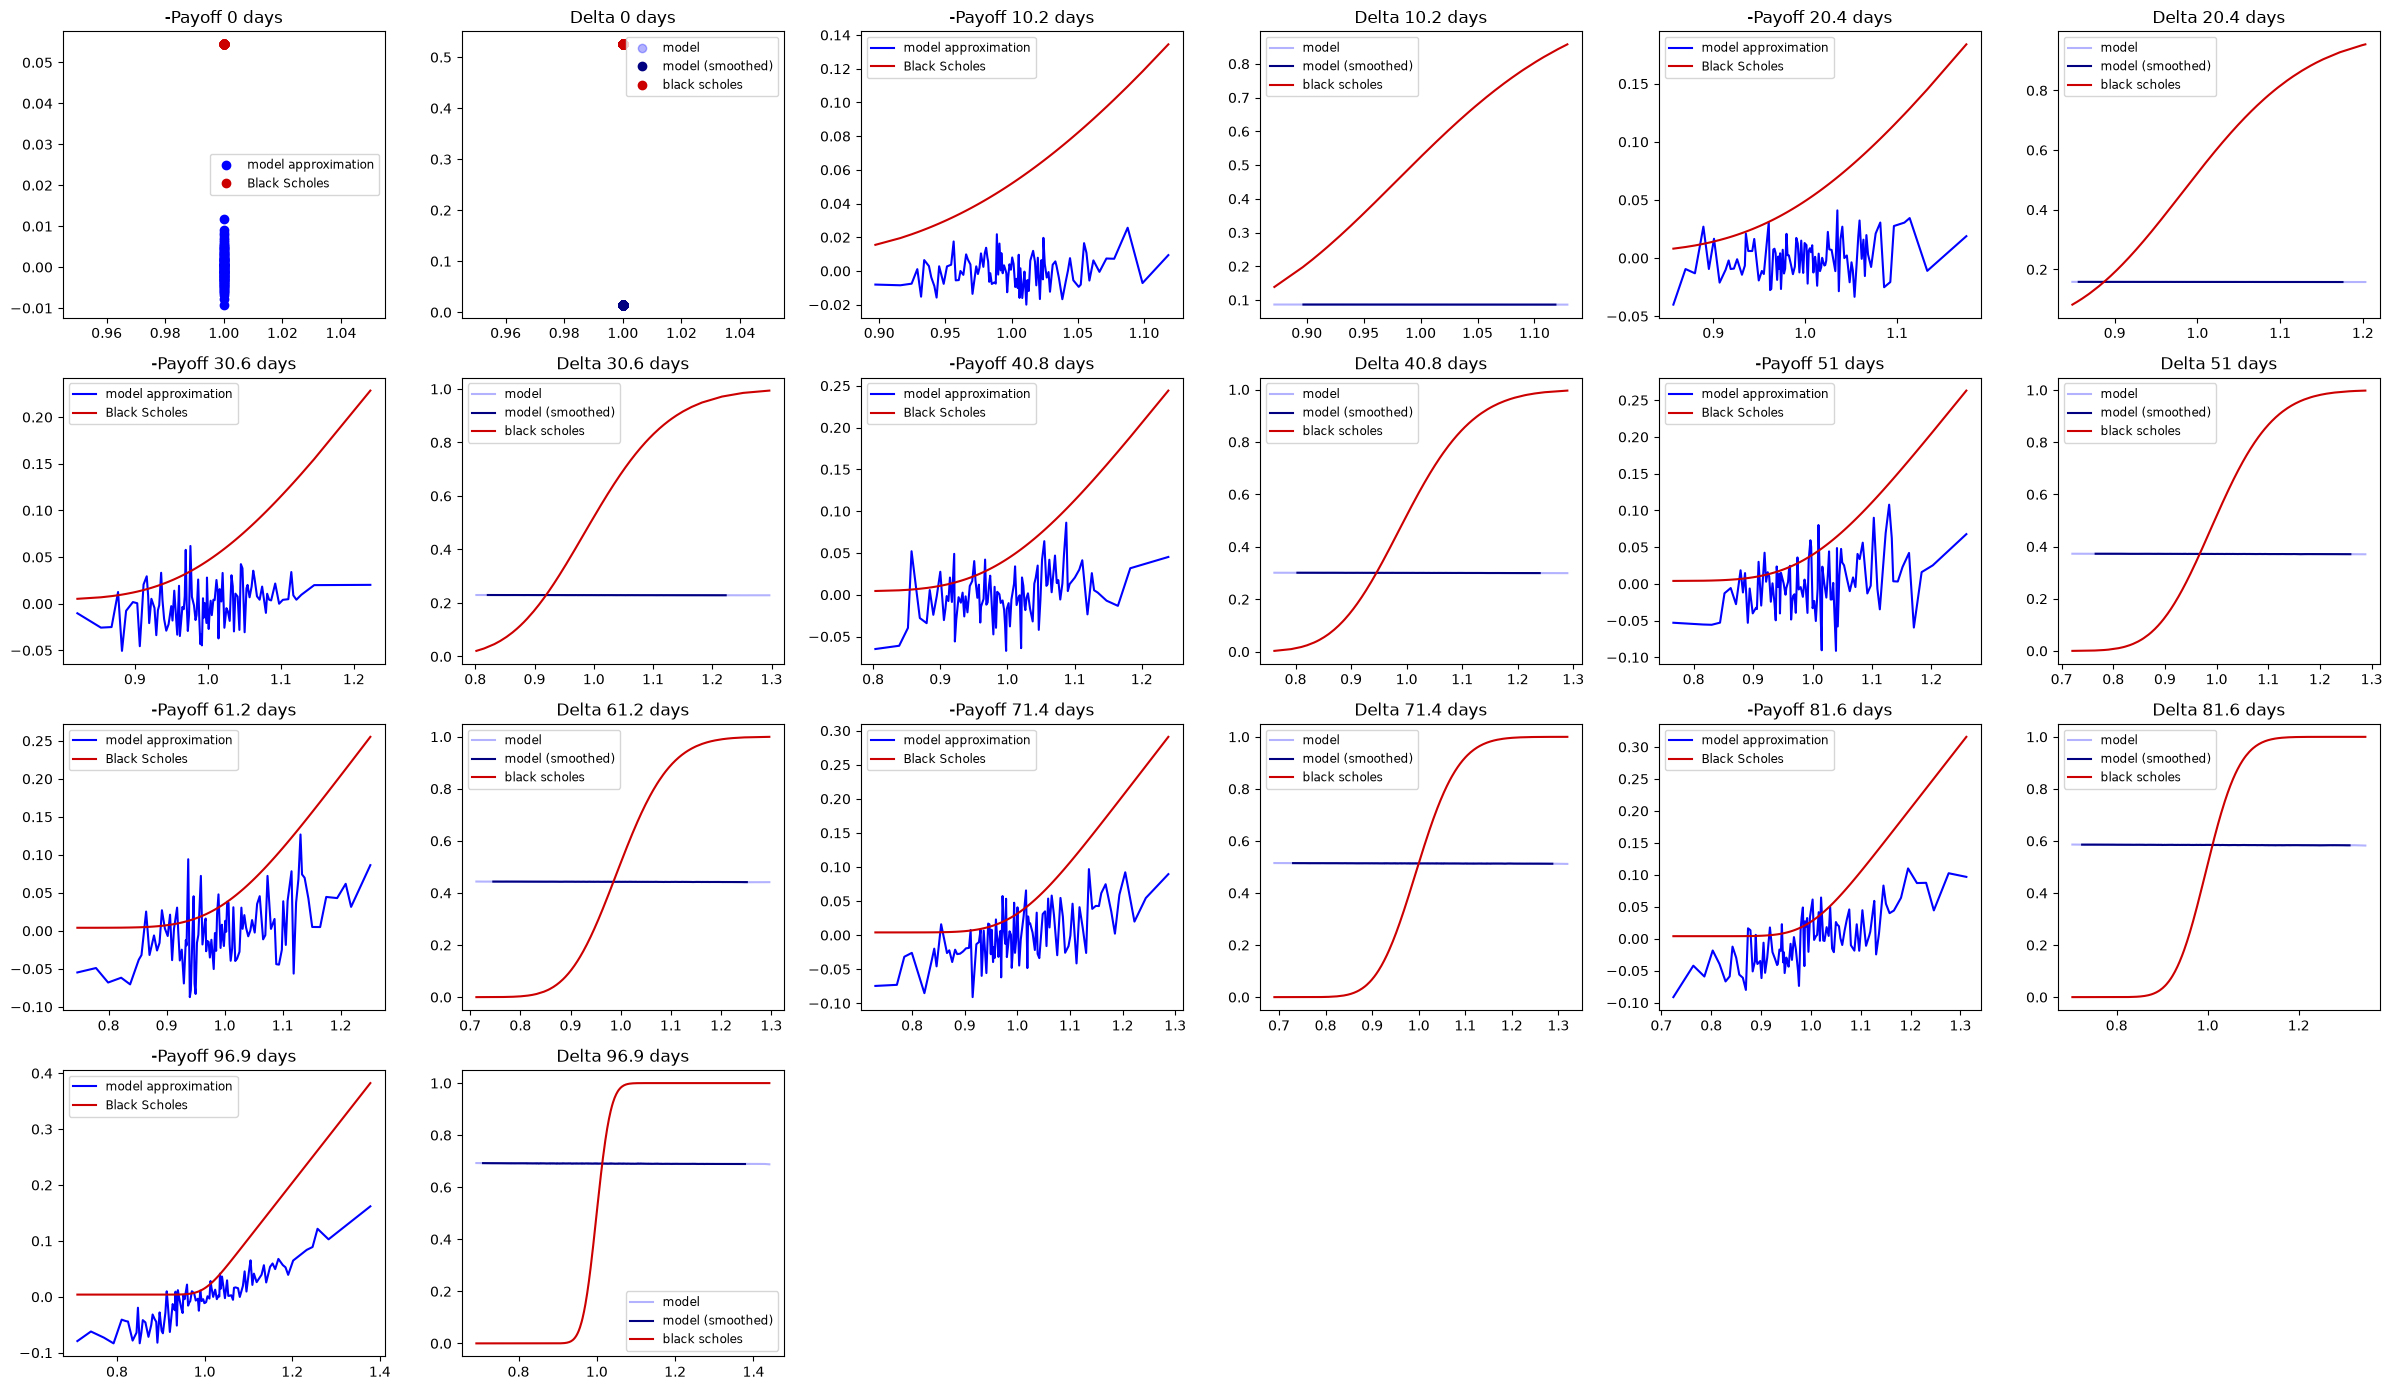

In [6]:
cfg = get_config("bs_nodrift", mode=MODE)
n_samples = get_samples(cfg["samples"])
n_epochs = get_epochs(cfg["epochs"])

world_cfg = WorldConfig(samples=n_samples, steps=cfg["steps"], black_scholes=True, rvol=cfg["rvol"], drift=cfg["drift"], cost_s=cfg["cost_s"])
gym = GymConfig(agent=AgentConfig(depth=cfg["depth"], width=cfg["width"], activation=cfg["activation"]), utility=cfg["utility"], lmbda=cfg["lmbda"])
train_cfg = TrainConfig(epochs=n_epochs, batch_size=min(cfg["batch_size"], n_samples), learning_rate=cfg["lr"], clipvalue=cfg["clipvalue"], global_clipnorm=cfg["global_clipnorm"])

world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 10, 50), seed=1)
nodrift_fit = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 4), checkpoint_dir=CHECKPOINTS)

try:
    plot_training(nodrift_fit.result, nodrift_fit.train, nodrift_fit.val, world, val_world)
    plt.show()
    plot_blackscholes(world, nodrift_fit.train, gym, vol=world_cfg.rvol)
    plt.show()
except Exception as e:
    print(f"Plot note: {e}")


## 4. `bs_nodrift_exp2`: Zero Drift Exp2 with Clipping (Exp2, Lambda=10.0, LR=0.001)


  epoch 1/2: loss 0.18314 val 0.16891 best@0 (1.36s)


  epoch 2/2: loss 0.17947 val 0.16195 best@0 (0.04s)


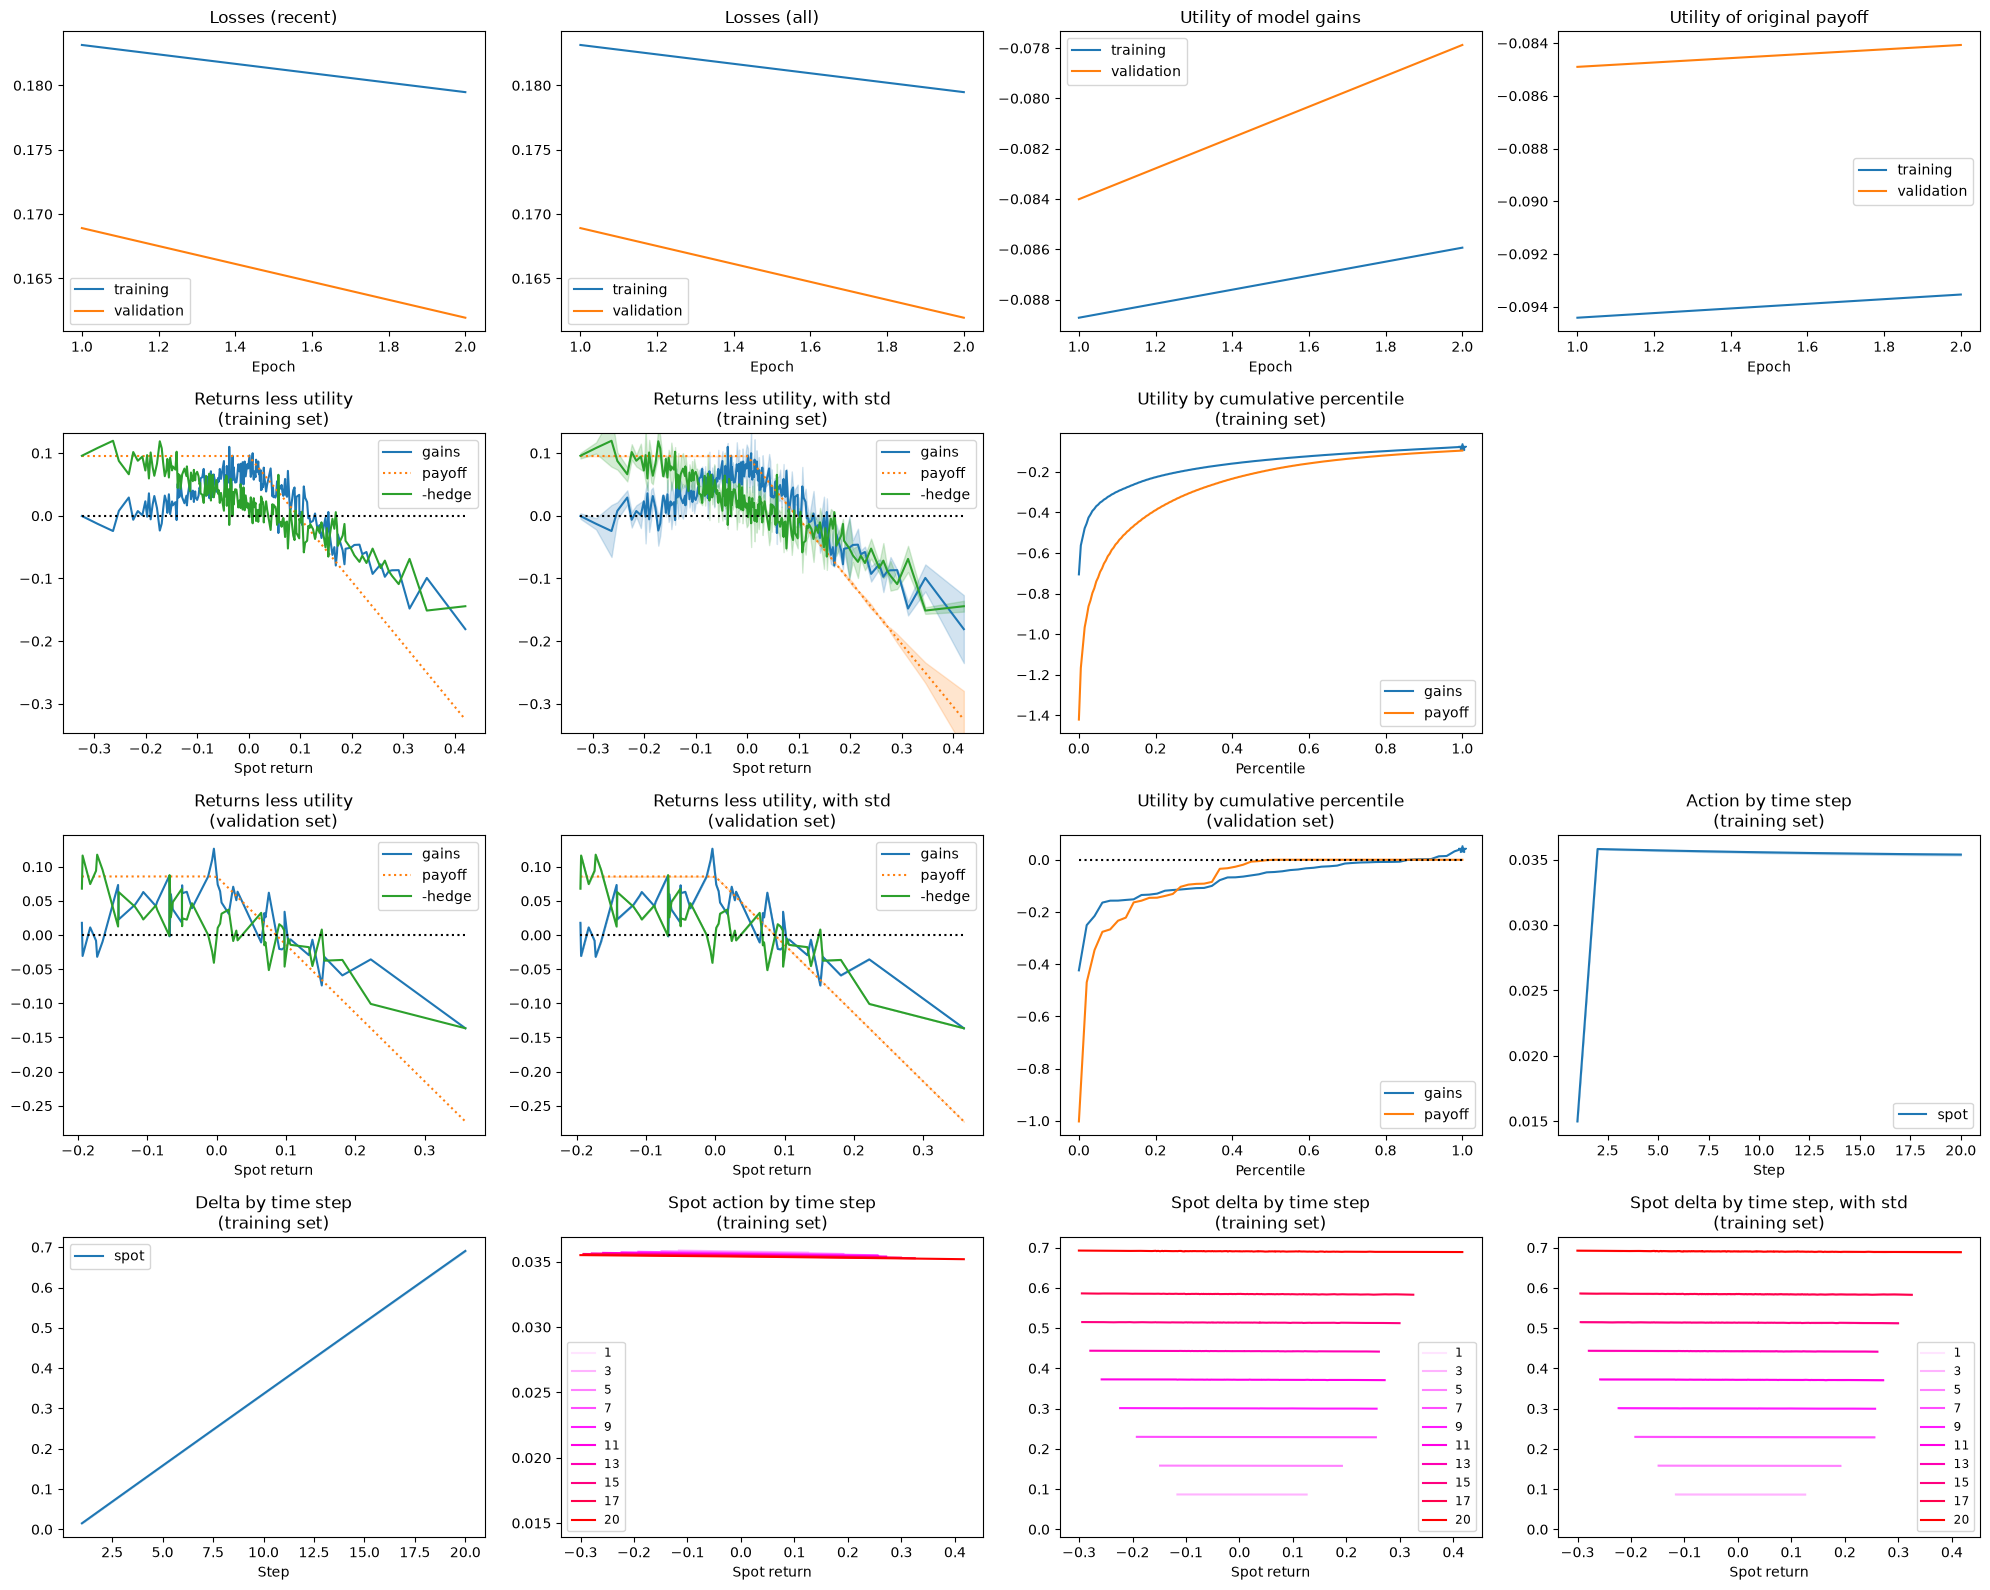

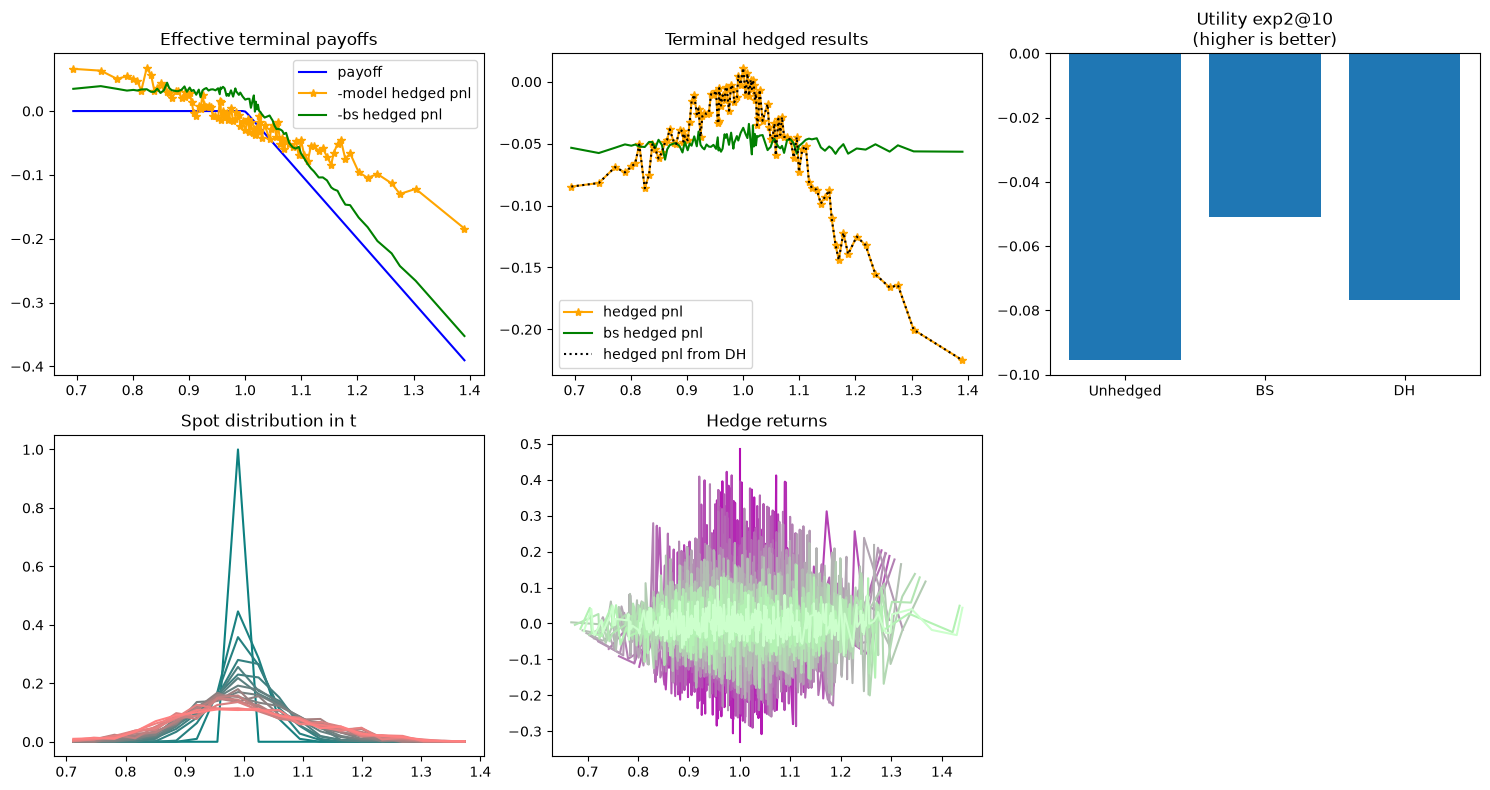

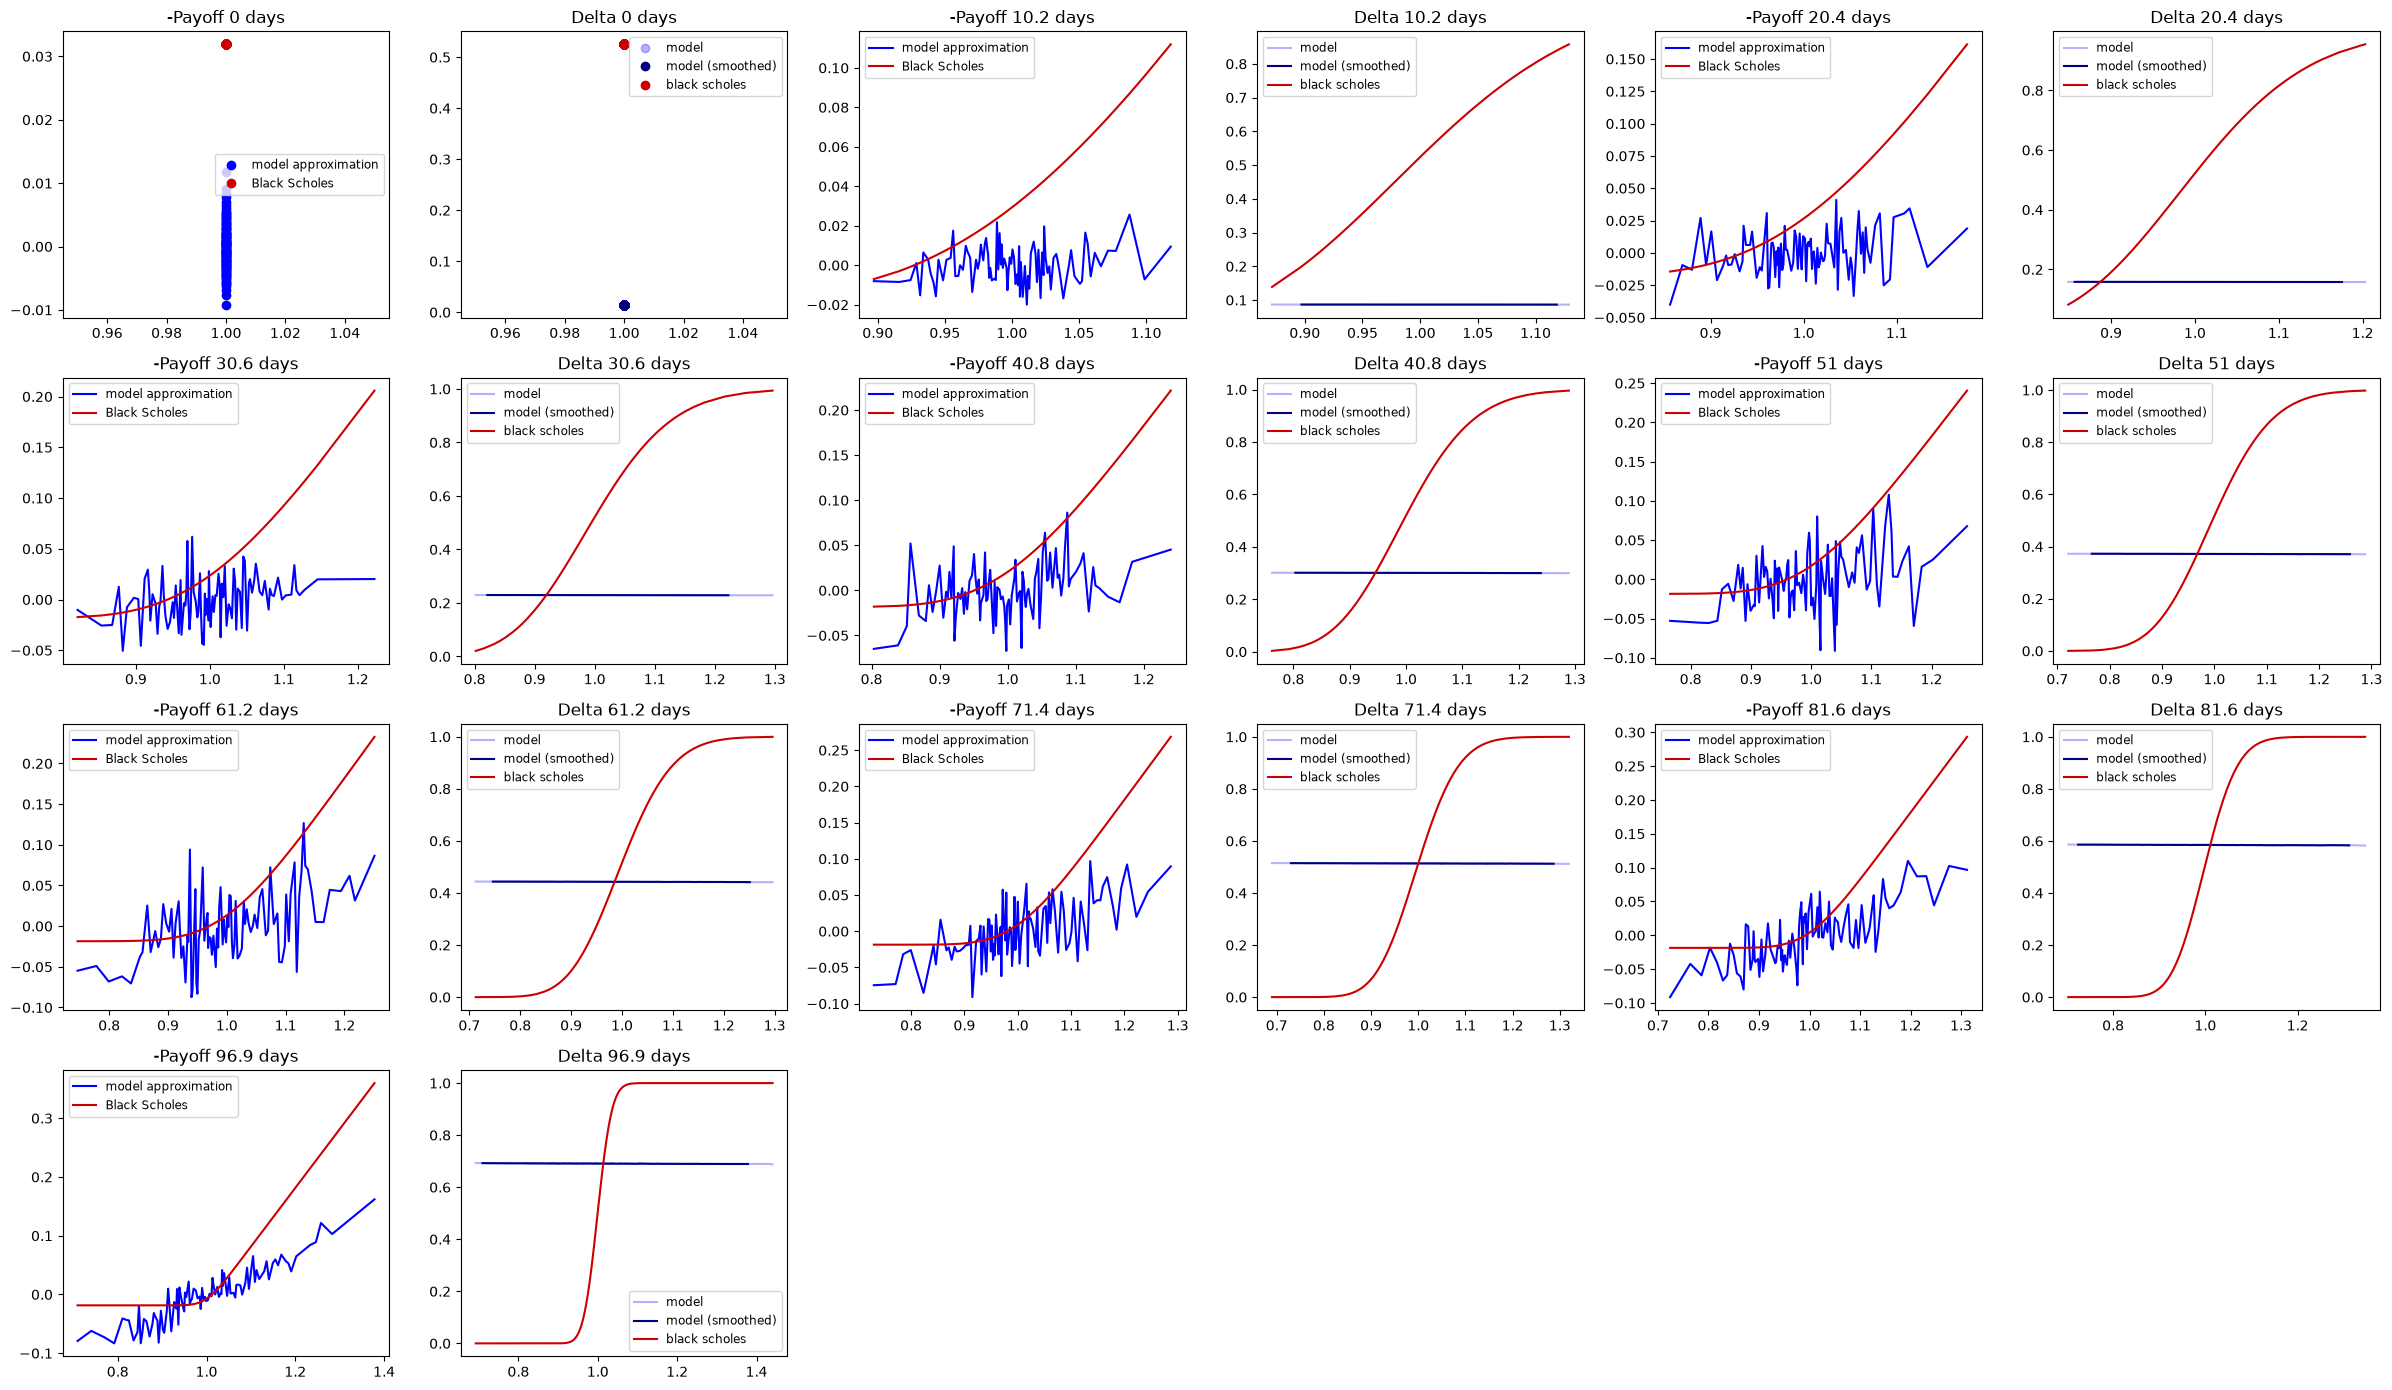

In [8]:
cfg = get_config("bs_nodrift_exp2", mode=MODE)
n_samples = get_samples(cfg["samples"])
n_epochs = get_epochs(cfg["epochs"])

world_cfg = WorldConfig(samples=n_samples, steps=cfg["steps"], black_scholes=True, rvol=cfg["rvol"], drift=cfg["drift"], cost_s=cfg["cost_s"])
gym = GymConfig(agent=AgentConfig(depth=cfg["depth"], width=cfg["width"], activation=cfg["activation"]), utility=cfg["utility"], lmbda=cfg["lmbda"])
train_cfg = TrainConfig(epochs=n_epochs, batch_size=min(cfg["batch_size"], n_samples), learning_rate=cfg["lr"], clipvalue=cfg["clipvalue"], global_clipnorm=cfg["global_clipnorm"])

world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 10, 50), seed=1)
nodrift_exp2_fit = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 4), checkpoint_dir=CHECKPOINTS)

try:
    plot_training(nodrift_exp2_fit.result, nodrift_exp2_fit.train, nodrift_exp2_fit.val, world, val_world)
    plt.show()
    plot_blackscholes(world, nodrift_exp2_fit.train, gym, vol=world_cfg.rvol)
    plt.show()
except Exception as e:
    print(f"Plot note: {e}")


## 5. `bs_small`: 10-Epoch Quick Hedging (CVaR, Lambda=2.0)


  epoch 1/2: loss 0.41650 val 0.38701 best@0 (1.89s)


  epoch 2/2: loss 0.62717 val 0.57338 best@0 (0.04s)


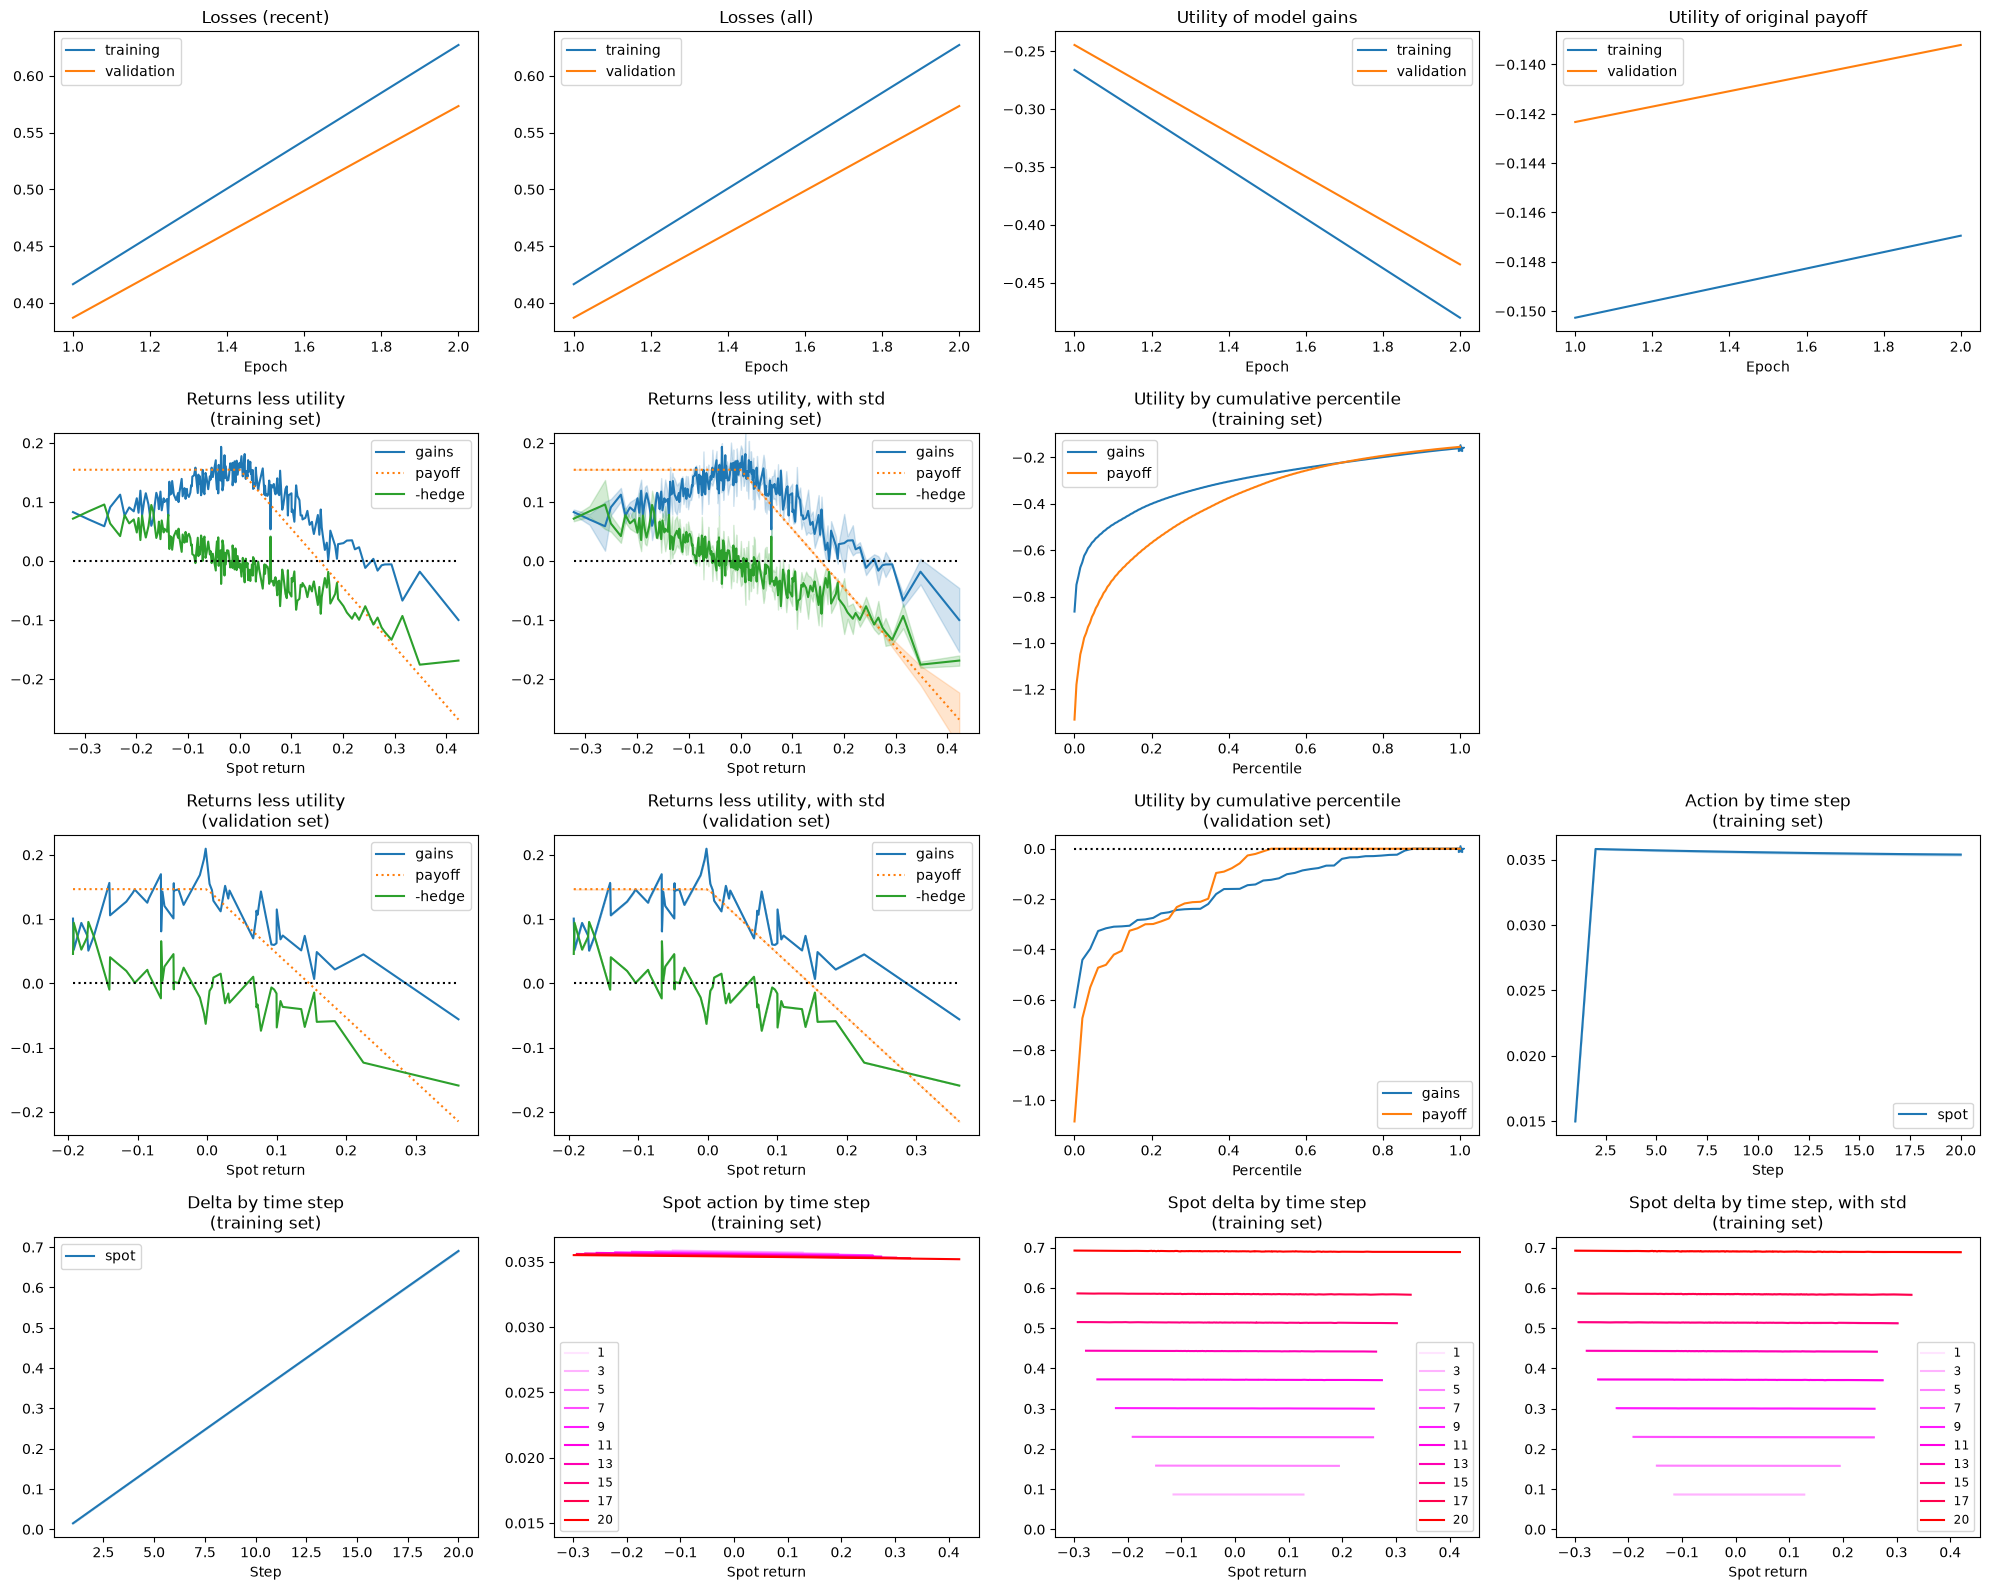

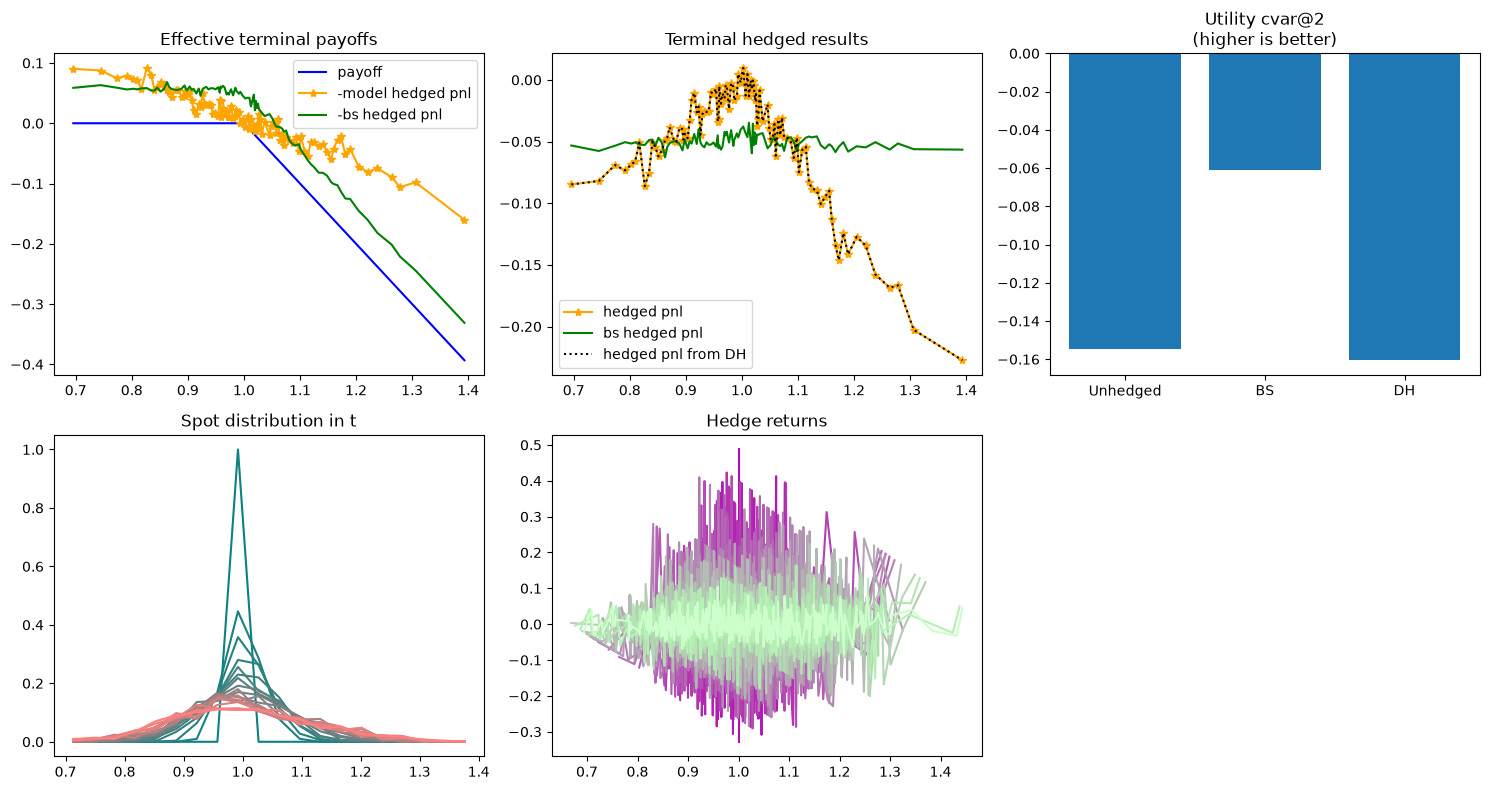

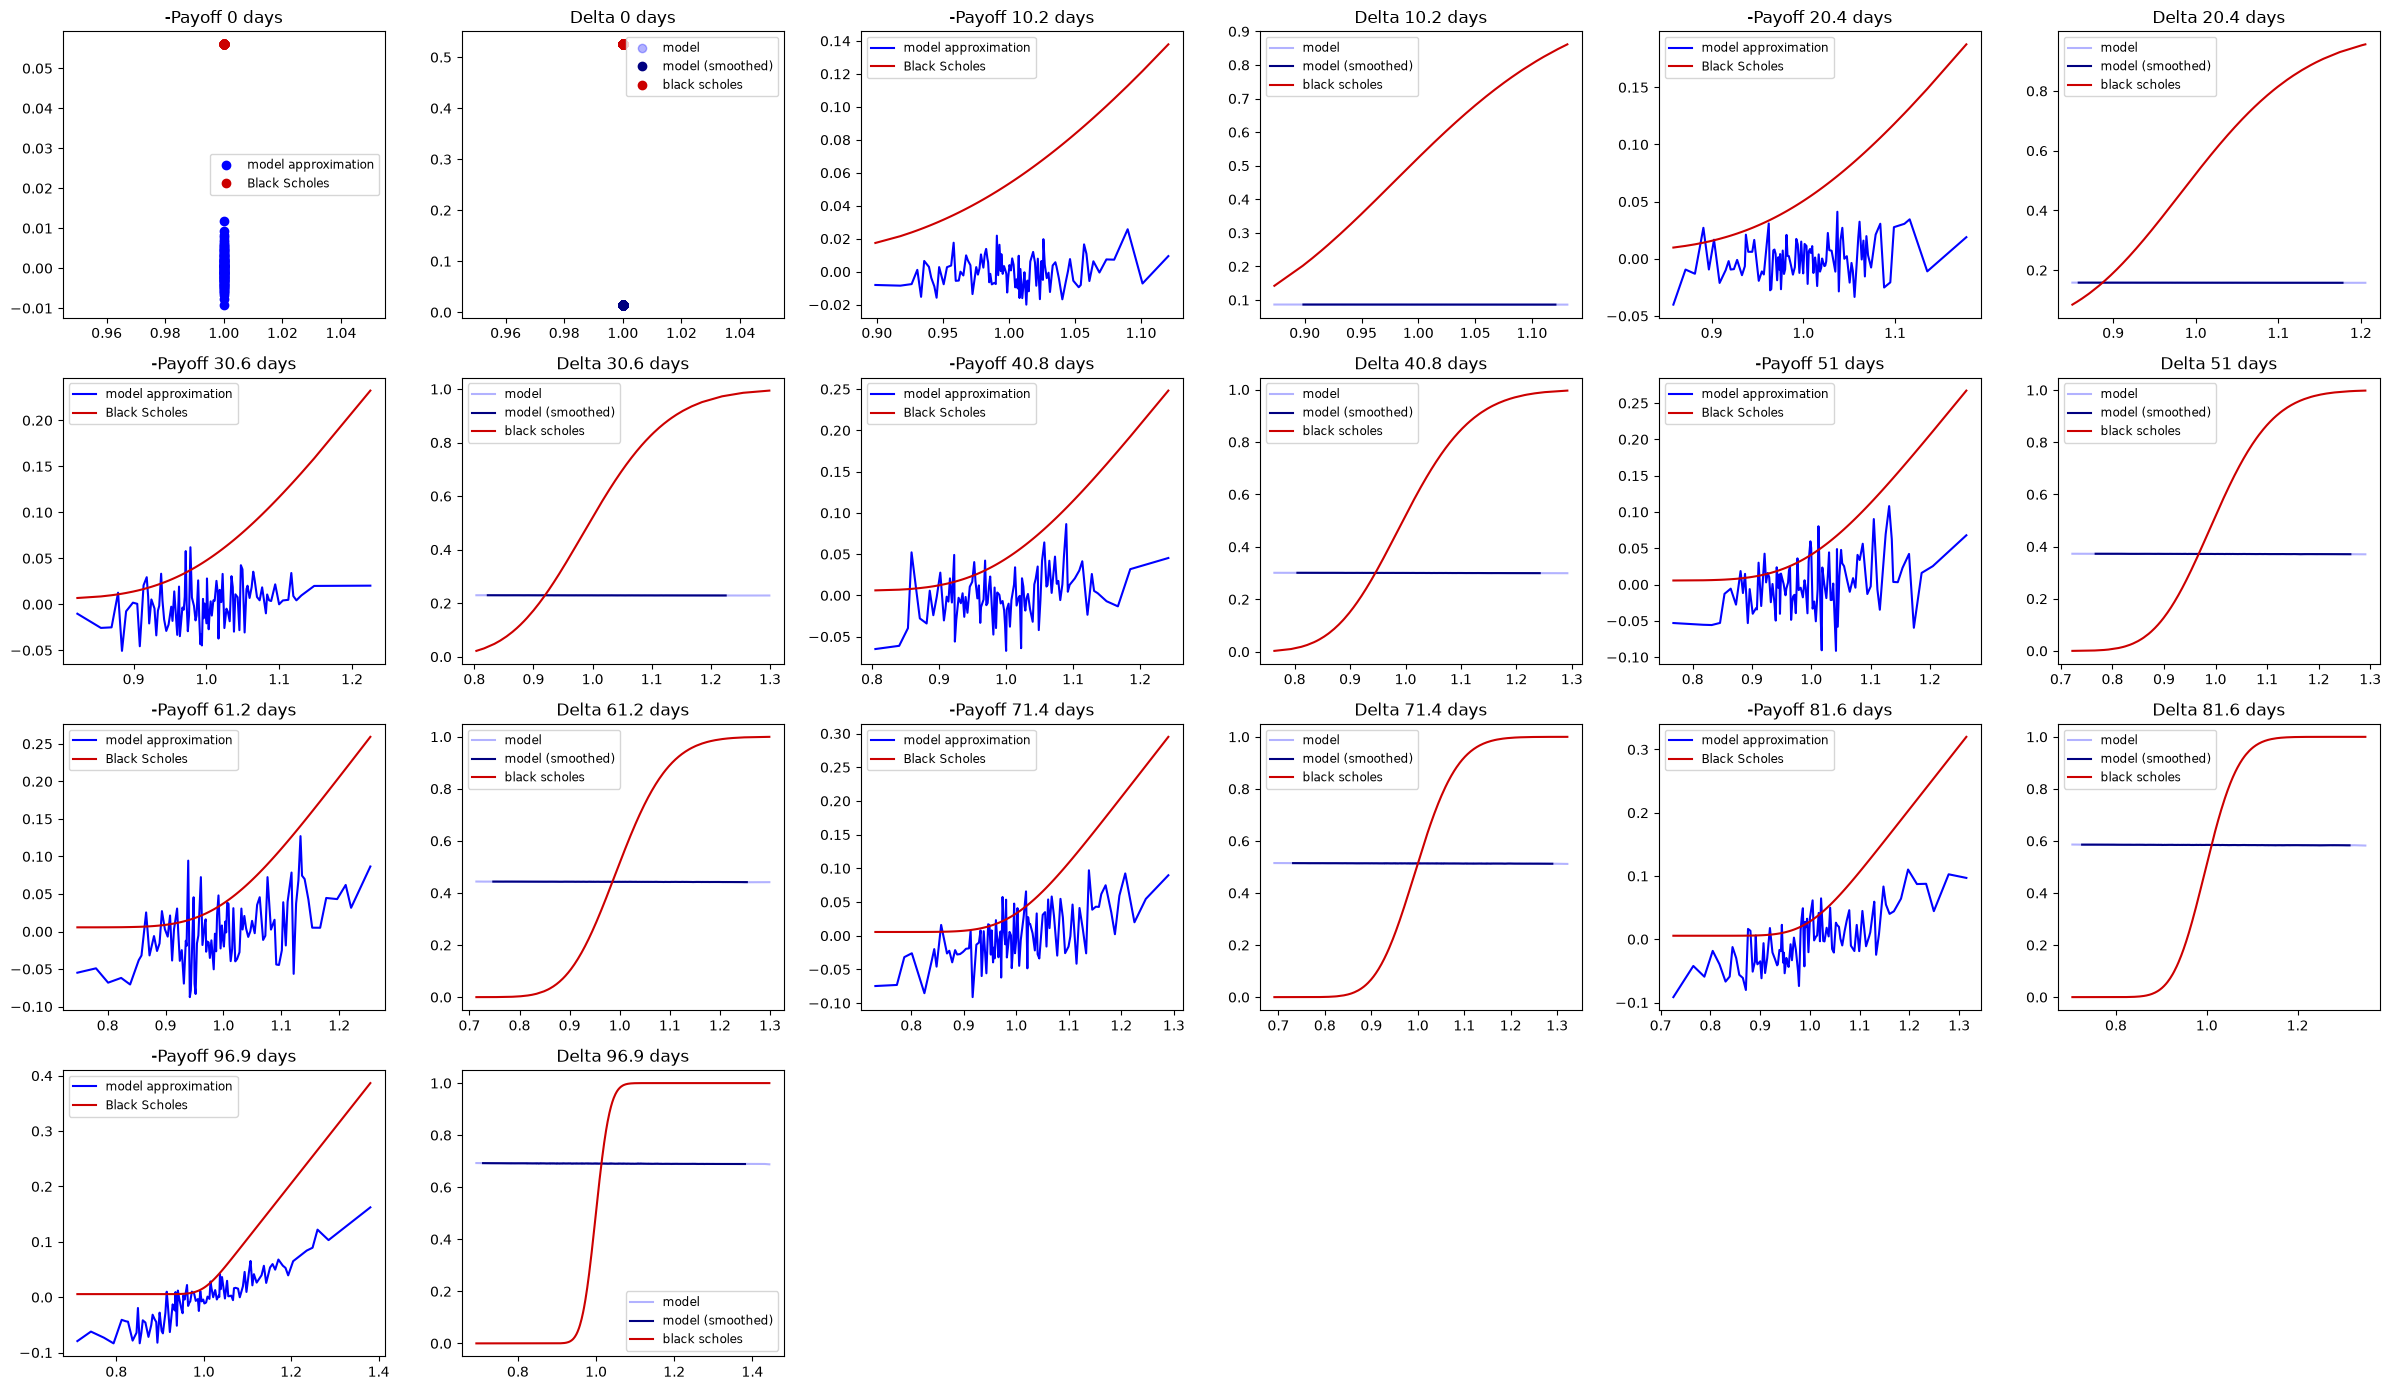

In [10]:
cfg = get_config("bs_small", mode=MODE)
n_samples = get_samples(cfg["samples"])
n_epochs = get_epochs(cfg["epochs"])

world_cfg = WorldConfig(samples=n_samples, steps=cfg["steps"], black_scholes=True, rvol=cfg["rvol"], drift=cfg["drift"], cost_s=cfg["cost_s"])
gym = GymConfig(agent=AgentConfig(depth=cfg["depth"], width=cfg["width"], activation=cfg["activation"]), utility=cfg["utility"], lmbda=cfg["lmbda"])
train_cfg = TrainConfig(epochs=n_epochs, batch_size=min(cfg["batch_size"], n_samples), learning_rate=cfg["lr"])

world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 10, 50), seed=1)
small_fit = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 2), checkpoint_dir=CHECKPOINTS)

try:
    plot_training(small_fit.result, small_fit.train, small_fit.val, world, val_world)
    plt.show()
    plot_blackscholes(world, small_fit.train, gym, vol=world_cfg.rvol)
    plt.show()
except Exception as e:
    print(f"Plot note: {e}")


### Summary of 5 Black-Scholes Variants
All 5 Black-Scholes configurations completed training.
